## Abstract and Introduction

### Abstract

This project addresses early capacity prediction for Ni-MH cells in a private battery-testing lab. The operational problem is straightforward: each cell needs a full galvanostatic discharge of up to 14 hours before a pass/fail decision can be made, plus up to 72 hours of deep reconditioning when needed. The goal is to predict $C_{\mathrm{final}}$ from the first 60–150 minutes of the discharge curve and issue an early decision without waiting for the full test.

We frame this as two parallel tasks: (1) binary classification (PASS if $C_{\mathrm{final}} \geq 5.0$ Ah) and (2) continuous capacity regression. For classical ML we extract 12 scalar features per observation window (derivatives, boundary values, mean/std of V and C) and evaluate Logistic Regression, Random Forest, SVM, XGBoost, and MLP over 10 windows from 30 to 300 minutes. For deep learning we feed 4-channel raw tensors ($V$, $C$, $\dot{V}$, $\dot{C}$, shape $151 \times 4$) into an LSTM and a 1D-CNN, using 8-fold Group K-Fold CV.

Results: the 1D-CNN outperforms the LSTM on this ~70-cell dataset, consistent with LSTMs needing more data to generalize. SVR is the most stable regression baseline among classical models. Gaussian noise augmentation (3 noisy copies per training fold, 4× total) reduces the generalization gap for the 1D-CNN. Across all models, a 90-minute observation window captures most of the predictable information, roughly 10% of the full test cycle.


### Introduction

Each used battery cell tested in this facility occupies a test station for up to 14 hours during a full discharge. If it fails and needs deep reconditioning (voltage-depression recovery), the total cycle can reach 72–90 hours. With dozens of cells tested in parallel, station throughput is a real constraint.

The core question: **can we predict a cell's final discharge capacity from the first 60–150 minutes of its discharge curve?** A reliable early predictor allows cutting the test short as soon as enough data is available, freeing up stations for other cells.

#### Project Objectives

1. **Early prediction feasibility**: test whether observation windows from 30 to 300 minutes (10 steps of 30 minutes each) contain enough information to classify or estimate $C_{\mathrm{final}}$.
2. **Feature engineering vs. raw signal**: compare hand-crafted features (classical ML) against end-to-end learning on raw sequences (deep learning).
3. **Classification vs. regression**: determine whether a direct binary classifier or a thresholded capacity regressor gives a better operational decision.

#### Notebook Structure

1. **Abstract and Introduction**: problem definition and project overview.
2. **Library Configuration and Data Loading**: imports, CSV ingestion, 10-second resampling, 80/20 train/Test split.
3. **Binary Classification**: 12-feature extraction, 5-model ROC-AUC sweep over 10 time windows, GridSearchCV tuning on the [60, 90] min window, Test evaluation with confusion matrices, learning curves.
4. **Regression**: 28-feature lagged extraction (4 blocks × 7 features), 3-model tuning over {60, 90, 120, 150} min with early-prediction preference ($\varepsilon = 0.025$ Ah), Test scatter plots.
5. **Deep Learning**: 4-channel tensors ($151 \times 4$), 8-fold Group CV for LSTM and 1D-CNN, then a repeat with Gaussian noise augmentation (4× training data).


### Physical Context: The Ni-MH Flat Plateau

Ni-MH cells behave differently from Li-ion: the discharge voltage stays nearly flat at ~1.2 V for roughly 80% of the cycle due to the dual-phase hydrogen insertion/extraction in the metal-hydride electrode. Only in the last ~20% does it drop sharply ("the knee"). This makes early-stage prediction harder, during the first 60–150 minutes, absolute voltage variation is small and partly masked by sensor noise.

This constraint motivates including $\dot{V} = \Delta V / \Delta t$ alongside the raw voltage: the slope of the plateau, even when tiny, correlates with the cell's state of health. The same reasoning drives the use of $\dot{C}$ as a channel in the deep learning models.

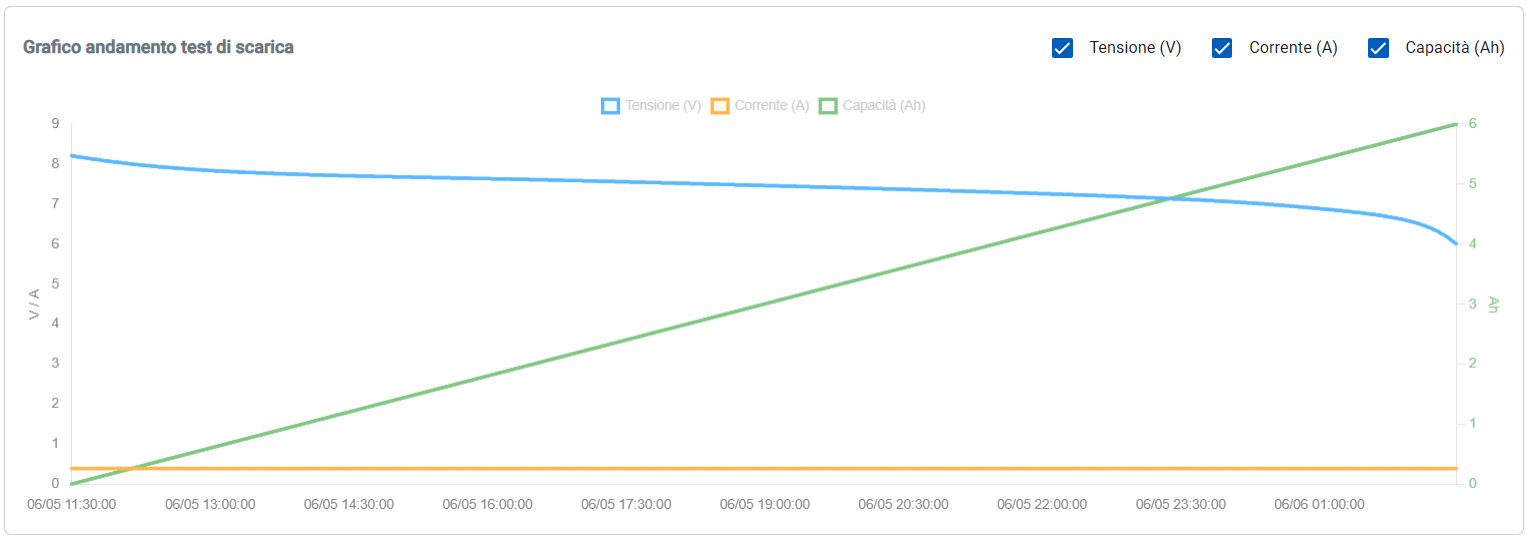


## Problem Formulation

### Dataset and Signal

Given $N$ independent discharge tests. Each test $\mathcal{S}_i$ is a multivariate time series sampled at uniform steps:

$$\mathcal{S}_i = \left\{ (V_{t,i},\; I_{t,i},\; C_{t,i}) \right\}_{t=1}^{T_i}$$

where $V$ is terminal voltage (V), $I$ is discharge current (A), and $C$ is cumulative capacity (Ah). The regression target is the total capacity at end of discharge:

$$C_{\mathrm{final}, i} = \max_t C_{t,i} = \sum_{t=1}^{T_i} I_{t,i} \cdot \Delta t$$

In this dataset the discharge current $I$ is practically constant (galvanostatic test), so the two informative channels are effectively $V$ and $C$.

### Two Prediction Tasks

**Classification.** The binary label is assigned by thresholding:
$$y_i = \mathbb{I}(C_{\mathrm{final}, i} \ge C_{\min}), \qquad C_{\min} = 5.0 \text{ Ah}$$
Classifiers predict $y_i$ directly, optimizing binary cross-entropy.

**Regression.** The continuous value $\hat{C}_{\mathrm{final}, i}$ is estimated by minimizing MSE. A binary decision can then be recovered post-hoc:
$$\hat{y}_i = \mathbb{I}(\hat{C}_{\mathrm{final}, i} \ge C_{\min})$$

Comparing these two approaches directly answers Objective 3: does optimizing over the full continuous target produce a better binary classifier than training the decision boundary directly?


### Partial Observation Constraint

Each model only sees the first $W$ minutes of the discharge. All data after minute $W$ is hidden:
$$\mathbf{X}_{\text{input}, i} = \{\mathbf{x}_{t,i}\}_{t=1}^{W}$$

The two functions to learn are:
$$f_{\text{class}}: \mathbb{R}^{W \times 3} \to \{0, 1\}, \qquad f_{\text{reg}}: \mathbb{R}^{W \times 3} \to \mathbb{R}^+$$

No future information ($t > W$) can enter the pipeline, not in feature computation, not in scaling, and not in label generation.


## Evaluation Metrics

To evaluate the goodness of the models, based on the different tasks, different metrics are used.

### Classification Metrics

Applied to Task 1 models and to thresholded regression outputs.

**Accuracy:** is the proportion of correct predictions a model makes out of the total predictions.
$$\text{Accuracy} = \frac{1}{N} \sum_{i=1}^{N} \mathbb{I}(Y_i = \hat{Y}_i)$$

**Precision**: certifying a degraded cell as PASS (False Positive) is the costliest error in this context:
$$\text{Precision} = \frac{TP}{TP + FP}$$

**Recall**: is the proportion of actual positive cases that the model successfully identifies.
$$\text{Recall} = \frac{TP}{TP + FN}$$

**ROC-AUC**: the primary metric throughout the temporal sweep and hyperparameter search. It is threshold-agnostic, so it allows comparing models at all possible operating points.

### Regression Metrics

The following metrics are applied to regression models, to evaluate the quality of the continuous predictions $\hat{C}_{\mathrm{final}, i}$.

**MSE (Mean Squared Error)**: quadratic, weights large errors more heavily:
$$\text{MSE} = \frac{1}{N} \sum_{i=1}^{N} (C_{\mathrm{final}, i} - \hat{C}_{\mathrm{final}, i})^2$$

**MAE (Mean Absolute Error)**: average error in Ah, directly interpretable operationally:
$$\text{MAE} = \frac{1}{N} \sum_{i=1}^{N} |C_{\mathrm{final}, i} - \hat{C}_{\mathrm{final}, i}|$$

**$R^2$ (Coefficient of Determination)**: fraction of capacity variance explained by the model:
$$R^2 = 1 - \frac{\sum_{i} (C_{\mathrm{final}, i} - \hat{C}_{\mathrm{final}, i})^2}{\sum_{i} (C_{\mathrm{final}, i} - \bar{C}_{\mathrm{final}})^2}$$


## Library Configuration and Data Loading

### Imports

All imports are in one cell so any missing package is caught immediately.

| Area | Libraries |
|---|---|
| Data | pandas, numpy, os, glob |
| Visualization | matplotlib |
| Classical ML | scikit-learn, xgboost |
| Reproducibility | RANDOM_SEED = 42 |

RANDOM_SEED = 42 is passed to every stochastic object (train_test_split, all estimators, np.random.seed). All results in this notebook are fully reproducible.


In [1]:
import os
import glob
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split,GroupKFold, StratifiedGroupKFold, GridSearchCV,learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, make_scorer, roc_auc_score, mean_absolute_error, r2_score, mean_squared_error
from sklearn.svm import SVC, SVR
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier, XGBRegressor
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import FitFailedWarning

warnings.filterwarnings(
    "ignore",
    message=r".*sklearn\.utils\.parallel\.delayed.*",
    category=UserWarning
)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


### Data Loading and Temporal Resampling

Each battery test is stored as a separate CSV file (;-separated). The loader   load_and_resample_battery_csv does three minor tasks to prepare the data for modeling:

1. **Parses Tempo** and sorts rows chronologically.
2. **Computes elapsed_min**: minutes elapsed since the start of that test, reset to 0 per file.
3. **Downsamples to 10-second resolution** (resample_sec=10): groups rows by 10-second windows and takes the column mean.

The 10-second downsampling matters for two reasons: it reduces high-frequency sensor noise, and it gives all files the same temporal grid, which is a prerequisite for computing $\Delta V / \Delta t$ with a consistent denominator across tests.

All loaded DataFrames go into battery_dict, keyed by filename.


In [2]:
def load_and_resample_battery_csv(file_path, resample_sec=10):
    """
    Reads a single telemetry CSV file, calculates elapsed time, and applies temporal
    downsampling based on a window of seconds (resample_sec).
    """
    # 1. Load the CSV file with the correct separator
    df = pd.read_csv(file_path, sep=';')
    
    # 2. Sequential sorting of the DataFrame based on the 'Tempo' column
    df['Tempo'] = pd.to_datetime(df['Tempo'], utc=True)
    df = df.sort_values('Tempo').reset_index(drop=True)
    
    # 3. Immediate calculation of the native time column (elapsed_min)
    # Indicates how many minutes have passed since the exact start of the test for this specific cell
    df['elapsed_min'] = (df['Tempo'] - df['Tempo'].iloc[0]).dt.total_seconds() / 60.0
    
    # 4. APPLYING DOWNSAMPLING (If requested)
    if resample_sec is not None and resample_sec > 1:
        # Set the timestamp as the temporal index to use Pandas' resample functions
        df = df.set_index('Tempo')
        
        # Aggregate by taking the mean of the physical values in the chosen second window
        df_resampled = df.resample(f'{resample_sec}s').mean()
        
        # Restore the index and correctly recalculate the elapsed time column
        df = df_resampled.reset_index()
        df['elapsed_min'] = (df['Tempo'] - df['Tempo'].iloc[0]).dt.total_seconds() / 60.0
        
    return df

In [3]:
RAW_CSV_FOLDER = "data\\raw_csvs"

csv_files = sorted(glob.glob(os.path.join(RAW_CSV_FOLDER, "*.csv")))

battery_dict = {}

for file_path in csv_files:
    file_name = os.path.basename(file_path)
    df_clean = load_and_resample_battery_csv(file_path, resample_sec=10)
    if df_clean is not None and len(df_clean) > 0:
        battery_dict[file_name] = df_clean


### Train/Test Split

File list is splitted, not individual rows, into 80% train/validation and 20% Test **before any feature extraction**. Splitting after feature extraction would let the scaler or any other statistic estimated on all files bleed into the test set.

The split is at the **file level**: all feature vectors from a given battery file go to either train or Test, never both. This group isolation is enforced here by train_test_split on the file list, and later by GroupKFold/StratifiedGroupKFold inside cross-validation.

file_Test_test is sealed here and only accessed in the final evaluation cell of each task.


In [4]:
list_unique_files = list(battery_dict.keys())

file_train_val, file_Test_test = train_test_split(
    list_unique_files, 
    test_size=0.20, 
    random_state=RANDOM_SEED,
    shuffle=True
)

# Binary Early Classification (PASS/FAIL)

Each capacity test is assigned a binary label according to the following rule:

$$y_i = \mathbb{I}(C_{\mathrm{final}, i} \ge 5.0 \text{ Ah})$$

A cell delivering $\geq 5.0$ Ah is **1 (PASS)**; below that it is **0 (FAIL)**. The 5.0 Ah threshold is the rated nominal capacity of these Ni-MH cells, cells below it are candidates for deep reconditioning.

Two summary DataFrames are built (summary_train_df, summary_test_df), one per partition, each with columns file_name, final_capacity, label. These are the ground-truth tables for the entire binary classification pipeline.


In [5]:
summary_train_df = pd.DataFrame(columns=['file_name', 'final_capacity', 'label'])
summary_test_df = pd.DataFrame(columns=['file_name', 'final_capacity', 'label'])

rows_train = []
rows_test = []

for file_name in file_train_val:
    df = battery_dict[file_name]
    final_capacity = df['Capacity (Ah)'].iloc[-1]
    label = 1 if final_capacity >= 5.0 else 0
    rows_train.append({
        'file_name': file_name,
        'final_capacity': final_capacity,
        'label': label
    })

for file_name in file_Test_test:
    df = battery_dict[file_name]
    final_capacity = df['Capacity (Ah)'].iloc[-1]
    label = 1 if final_capacity >= 5.0 else 0
    rows_test.append({
        'file_name': file_name,
        'final_capacity': final_capacity,
        'label': label
    })

summary_train_df = pd.DataFrame(rows_train)
summary_test_df = pd.DataFrame(rows_test)

## Feature Extraction

The raw signal has 3 channels (V, I, C), but, since I is constant (galvanostatic discharge), the informative channels are V and C. To give classical ML models enough signal, 12 scalar features are computed per observation window with extract_features_from_battery.

| Feature | Description |
|---|---|
| delta_voltage | $V_{\text{end}} - V_{\text{start}}$ |
| dv_dt | delta_voltage / W first finite difference of V |
| d2v_dt2 | $(V_{\text{end}} - 2V_{\text{mid}} + V_{\text{start}}) / W^2$ , centered second difference |
| mean_voltage | mean V over the window |
| std_voltage | std V over the window |
| delta_capacity | $C_{\text{start}} - C_{\text{end}}$ , capacity discharged in the window |
| dC_dt | delta_capacity / W |
| d2C_dt2 | centered second difference of C |
| voltage_start, voltage_end | boundary V values |
| capacity_start, capacity_end | boundary C values |

For the temporal sweep, 10 consecutive non-overlapping windows are evaluated: [0–30], [30–60], ..., [270–300] minutes. Each (file, window) pair produces one row, so the full training matrix has $N_{\text{files}} \times 10$ rows.


In [6]:
def extract_features_from_battery(df, window_minutes=60, starting_minute = 0):
    """
    Extracts features from a battery DataFrame truncated to a specific time window.
    
    Parameters:
    - df: DataFrame containing the battery telemetry data.
    - window_minutes: The time window in minutes to truncate the data.
    - starting_minute: The starting minute from which to begin truncation.
    
    Returns:
    - A dictionary of extracted features.
    """
    # Truncate the DataFrame to the specified time window
    truncated_df = df[(df['elapsed_min'] >= starting_minute) & (df['elapsed_min'] <= starting_minute + window_minutes)]
    
    # Calculate features
    delta_voltage = truncated_df['Tensione (V)'].iloc[-1] - truncated_df['Tensione (V)'].iloc[0] if len(truncated_df) > 1 else np.nan
    dv_dt = delta_voltage / window_minutes if not np.isnan(delta_voltage) else np.nan
    d2v_dt2 = (truncated_df['Tensione (V)'].iloc[-1] - 2 * truncated_df['Tensione (V)'].iloc[len(truncated_df)//2] + truncated_df['Tensione (V)'].iloc[0]) / (window_minutes**2) if len(truncated_df) > 2 else np.nan
    v_mean = truncated_df['Tensione (V)'].mean() if not truncated_df.empty else np.nan
    v_std = truncated_df['Tensione (V)'].std() if not truncated_df.empty else np.nan
    delta_C = truncated_df['Capacity (Ah)'].iloc[0] - truncated_df['Capacity (Ah)'].iloc[-1] if len(truncated_df) > 1 else np.nan
    dC_dt = delta_C / window_minutes if not np.isnan(delta_C) else np.nan
    d2C_dt2 = (truncated_df['Capacity (Ah)'].iloc[-1] - 2 * truncated_df['Capacity (Ah)'].iloc[len(truncated_df)//2] + truncated_df['Capacity (Ah)'].iloc[0]) / (window_minutes**2) if len(truncated_df) > 2 else np.nan
    v_start = truncated_df['Tensione (V)'].iloc[0] if not truncated_df.empty else np.nan
    v_end = truncated_df['Tensione (V)'].iloc[-1] if not truncated_df.empty else np.nan
    c_start = truncated_df['Capacity (Ah)'].iloc[0] if not truncated_df.empty else np.nan
    c_end = truncated_df['Capacity (Ah)'].iloc[-1] if not truncated_df.empty else np.nan
    
    return {
        'start_time': starting_minute,
        'end_time': starting_minute + window_minutes,
        'delta_voltage': delta_voltage,
        'dv_dt': dv_dt,
        'd2v_dt2': d2v_dt2,
        'mean_voltage': v_mean,
        'std_voltage': v_std,
        'delta_capacity': delta_C,
        'dC_dt': dC_dt,
        'd2C_dt2': d2C_dt2,
        'voltage_start': v_start,
        'voltage_end': v_end,
        'capacity_start': c_start,
        'capacity_end': c_end
    }

## Feature Matrix Construction

The function extract_features_from_battery is applied to every (file, window) pair and the results are stacked into df_classification_train and df_classification_test. Each row has the 12 features plus file_name and window as metadata columns. Labels are joined from summary_train_df/summary_test_df in the evaluation functions.


In [7]:
START_WINDOW_TEST = [0,30,60,90,120,150,180,210,240,270]
END_WINDOW_TEST = [30,60,90,120,150,180,210,240,270,300]
features_train_list = []
features_test_list = []

for file_name in file_train_val:
    df_train = battery_dict[file_name]
    for i in range(len(START_WINDOW_TEST)):
        features_train = extract_features_from_battery(df_train, window_minutes=END_WINDOW_TEST[i], starting_minute=START_WINDOW_TEST[i])
        features_train['file_name'] = file_name
        features_train['window'] = END_WINDOW_TEST[i]
        features_train_list.append(features_train)

for file_name in file_Test_test:
    df_test = battery_dict[file_name]
    for i in range(len(START_WINDOW_TEST)):
        features_test = extract_features_from_battery(df_test, window_minutes=END_WINDOW_TEST[i], starting_minute=START_WINDOW_TEST[i])
        features_test['file_name'] = file_name
        features_test['window'] = END_WINDOW_TEST[i]
        features_test_list.append(features_test)

df_classification_train = pd.DataFrame(features_train_list)
df_classification_test = pd.DataFrame(features_test_list)

# Model Evaluation strategy

The first chapter introduced the parameter $W$ to underline the data the model is going to see. The goal of the evaluation is to compare the ROC-AUC (Receiver Operating Characteristics - Area Under the Curve) of different time windows, to find the earliest window that still contains enough information to make a reliable prediction. The evaluation is done on the Test set, which was never seen during training. The expectation is that the AUC-ROC curve will increase with the window size, the choice of the window is a trade-off between the time spent on the test and the reliability of the prediction.

In [8]:
def evaluate_model_on_window(df_matrix, model, n_splits=3):
    """
    Executes the scaling, training, and out-of-fold testing of models on the
    matrix generated with your feature extraction method.
    Parameters:
    - df_matrix: DataFrame containing the features and labels for a specific time window.
    - model: The machine learning model to be evaluated.
    - n_splits: Number of splits for StratifiedGroupKFold cross-validation.
    Returns:
    - The mean ROC-AUC score across the folds, or NaN if evaluation is not possible
      due to insufficient unique groups or classes.
    """
    # Metadata columns or target to be strictly excluded from model fitting
    exclude_cols = {'file_name', 'label', 'start_time', 'end_time'}
    feature_cols = [c for c in df_matrix.columns if c not in exclude_cols]
    
    X = df_matrix[feature_cols].values
    y = df_matrix['label'].values
    groups = df_matrix['file_name'].values
    
    if len(np.unique(groups)) < n_splits or len(np.unique(y)) < 2:
        return np.nan
        
    sgkf = StratifiedGroupKFold(n_splits=n_splits)
    pipeline = Pipeline([('scaler', StandardScaler()), ('clf', model)])
    
    oof_preds = np.zeros(len(df_matrix))
    
    for train_idx, val_idx in sgkf.split(X, y, groups):
        # TRAINING PHASE
        pipeline.fit(X[train_idx], y[train_idx])
        
        # TEST PHASE (Out-of-Fold Internal Validation)
        if hasattr(pipeline, 'predict_proba'):
            oof_preds[val_idx] = pipeline.predict_proba(X[val_idx])[:, 1]
        else:
            oof_preds[val_idx] = pipeline.decision_function(X[val_idx])
            
    return roc_auc_score(y, oof_preds)

def evaluate_models(
        models, 
        window_start, 
        window_end,
        battery_dict, 
        summary_train_df, 
        file_train_val):
    
    history = {name: [] for name in models.keys()}

    # Main cycle of feature extraction and model evaluation
    for i in range(len(window_start)):
        records_finestra = []
        w_end = window_end[i]
        w_start = window_start[i]
        
        for file_name in file_train_val:
            df_bat = battery_dict[file_name]
            label = summary_train_df[summary_train_df['file_name'] == file_name]['label'].values[0]
            
            feat_dict = extract_features_from_battery(df_bat, window_minutes=w_end, starting_minute=w_start)
            
            # Data sanitization in case of missing or invalid feature extraction
            if feat_dict is not None and not np.isnan(feat_dict['delta_voltage']):
                feat_dict['label'] = label
                feat_dict['file_name'] = file_name
                records_finestra.append(feat_dict)
                
        if not records_finestra:
            for name in models.keys(): history[name].append(np.nan)
            continue
            
        df_matrice_w = pd.DataFrame(records_finestra)
        
        # Fill any missing values in the DataFrame to ensure model evaluation can proceed without errors
        df_matrice_w = df_matrice_w.bfill().ffill()
        
        # Evaluation
        for name, model in models.items():
            auc_score = evaluate_model_on_window(df_matrice_w, model)
            history[name].append(auc_score)

    return history

def plot_roc_auc_over_time(history, test_windows):
    """
    Plots the ROC-AUC scores over time for different models.
    
    Parameters:
    - history: Dictionary containing model names as keys and lists of ROC-AUC scores as values.
    - test_windows: List of time windows corresponding to the ROC-AUC scores.
    """
    plt.figure(figsize=(10, 6))

    for name, scores in history.items():
        plt.plot(test_windows, scores, marker='o', lw=2, label=name)

    plt.axhline(0.90, color='r', linestyle='--', alpha=0.6, label='Acceptability Threshold (0.90)')
    plt.title("Evolution of Early Separability (Binary Classification Task)")
    plt.xlabel("Partial Observation Time (Minutes from the start of the discharge)")
    plt.ylabel("Mean Out-of-Fold ROC-AUC")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

# Models designing

In order to solve the binary classification task, 5 different models are evaluated. The models are:
- Logistic Regression
- Random Forest
- Support Vector Machine
- XGBoost
- Multi-Layer Perceptron (MLP)

## Logistic Regression

Logistic Regression model is a linear model that uses the logistic function to model the probability of a binary outcome. It is simple, interpretable, and often serves as a baseline for classification tasks.

The formula that defines the logistic regression model is:
$$P(y=1|X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 X_1 + \beta_2 X_2 + ... + \beta_n X_n)}}$$

Where: 
- $P(y=1|X)$ is the probability of the positive class given the input features $X$.
- $\beta_0$ is the intercept term.
- $\beta_1, \beta_2, ..., \beta_n$ are the coefficients for the input features $X_1, X_2, ..., X_n$.

**Training Phase**: The model is trained by maximizing the likelihood of the observed data, which is equivalent to minimizing the binary cross-entropy loss function.

Explained by the maximization of the log-likelihood function:

$$\mathcal{L}(\beta) = \sum_{i=1}^{N} \left[ y_i \log(P(y_i=1|X_i)) + (1 - y_i) \log(1 - P(y_i=1|X_i)) \right]$$

Where:
- $N$ is the number of training samples.


## Random Forest

Random Forest is an ensemble learning method that constructs multiple decision trees during training and outputs the mode of the classes (classification) or mean prediction (regression) of the individual trees. It is robust to overfitting and can handle high-dimensional data.

The model prediction for a Random Forest classifier is given by:

$$\hat{y} = \text{mode}\{T_1(X), T_2(X), ..., T_m(X)\}$$

Where:
- $\hat{y}$ is the predicted class label.
- $T_1, T_2, ..., T_m$ are the individual decision trees in the forest.

**Training Phase:** The model is trained by constructing multiple decision trees on different subsets of the training data and aggregating their predictions.

The training process involves:
1. **Bootstrap Sampling**: Randomly sample the training data with replacement to create multiple subsets
2. **Tree Construction**: For each subset, build a decision tree by recursively splitting the data based on feature values to minimize impurity (e.g., Gini impurity or entropy).

## Support Vector Machine

Support Vector Machine (SVM) is a supervised learning algorithm that finds the optimal hyperplane that separates data points of different classes. The model was originally designed for binary classification tasks in a bi-dimensional space, but it can be extended to higher dimensions and non-linear decision boundaries using kernel functions. This is the version used in this notebook, with a radial basis function (RBF) kernel.

The goal of SVM is to maximize the margin between the classes, which is defined as the distance between the hyperplane and the nearest data points from each class (support vectors). The SVM models tries to find the hyperplane that maximizes this margin while minimizing classification errors.

An hyperplan in a bi-dimensional space can be defined as:
$$w^T x + b = 0$$

The RBF kernel function is defined as:
$$K(x_i, x_j) = \exp\left(-\gamma \|x_i - x_j\|^2\right)$$

Where:
- $\gamma$ is a hyperparameter that controls the influence of individual support vectors.

**Training Phase:** The model is trained by solving a convex optimization problem that maximizes the margin while minimizing classification errors. This involves finding the optimal values for the weight vector $w$ and bias $b$.

The optimization problem can be formulated as:
$$\min_{w, b} \frac{1}{2} \|w\|^2 + C \sum_{i=1}^{N} \xi_i$$

## XGBoost

XGBoost (Extreme Gradient Boosting) is an optimized implementation of gradient boosting that is designed for speed and performance. It builds an ensemble of decision trees in a sequential manner, where each tree corrects the errors of the previous ones. XGBoost is known for its efficiency, scalability, and ability to handle missing data.

The prediction for XGBoost is given by:
$$\hat{y} = \sum_{k=1}^{K} f_k(X)$$

Where:
- $\hat{y}$ is the predicted output.
- $f_k(X)$ is the prediction from the $k$-th decision tree in the ensemble.

**Training Phase:** The model is trained by constructing multiple decision trees on different subsets of the training data and aggregating their predictions.

## Multi-Layer Perceptron (MLP)

A Multi-Layer Perceptron (MLP) is a type of feedforward artificial neural network that consists of multiple layers of neurons, including an input layer, one or more hidden layers, and an output layer. Each neuron in a layer is connected to every neuron in the subsequent layer, allowing the network to learn complex non-linear relationships in the data.

The output of an MLP can be expressed as:
$$\hat{y} = f(W^{(L)} \cdot f(W^{(L-1)} \cdot ... f(W^{(1)} \cdot X + b^{(1)}) ... + b^{(L-1)}) + b^{(L)})$$

Where:
- $\hat{y}$ is the predicted output.
- $X$ is the input feature vector.
- $W^{(l)}$ and $b^{(l)}$ are the weight matrix and bias vector for the $l$-th layer.
- $f$ is the activation function applied element-wise.

**Training Phase:** The model is trained using backpropagation, which involves computing the gradients of the loss function with respect to the weights and biases, and updating them using an optimization algorithm (e.g., stochastic gradient descent).

Backpropagation consists of two main steps:
1. **Forward Pass**: Compute the predicted output $\hat{y}$ by passing the input $X$ through the network.
2. **Backward Pass**: Compute the gradients of the loss function with respect to the weights and biases using the chain rule, and update the parameters accordingly.

The loss function used for training is typically the mean squared error (MSE) for regression tasks or binary cross-entropy for classification tasks, which is minimized during the training process.

The minimization of the loss function can be expressed as:
$$\min_{W, b} \frac{1}{N} \sum_{i=1}^{N} L(y_i, \hat{y}_i)$$

Where:
- $L(y_i, \hat{y}_i)$ is the loss function measuring the difference between the true label $y_i$ and the predicted output $\hat{y}_i$.
- $N$ is the number of training samples.
- $W$ and $b$ are the weights and biases of the network.

In [9]:
models = {
    "Logistic Regression": LogisticRegression(
        solver='liblinear', class_weight='balanced',
        max_iter=1000, random_state=RANDOM_SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=8, class_weight='balanced',
        n_jobs=-1, random_state=RANDOM_SEED
    ),    
    "SVM": CalibratedClassifierCV(
        estimator=SVC(
            kernel='rbf', C=1.0, gamma='scale', 
            class_weight='balanced', random_state=RANDOM_SEED
        ),
        method='sigmoid', cv=3, ensemble=False
    ),
    "XGBoost": XGBClassifier(
        n_estimators=100, max_depth=4, learning_rate=0.05,
        n_jobs=-1, eval_metric='logloss', random_state=RANDOM_SEED
    ),
    "MLP": MLPClassifier(
        hidden_layer_sizes=(64, 32), activation='relu', solver='adam',
        alpha=0.01, max_iter=300, early_stopping=True, random_state=RANDOM_SEED
    ),
}

history = evaluate_models(
    models=models,
    window_start=START_WINDOW_TEST,
    window_end=END_WINDOW_TEST,
    battery_dict=battery_dict,
    summary_train_df=summary_train_df,
    file_train_val=file_train_val)
    

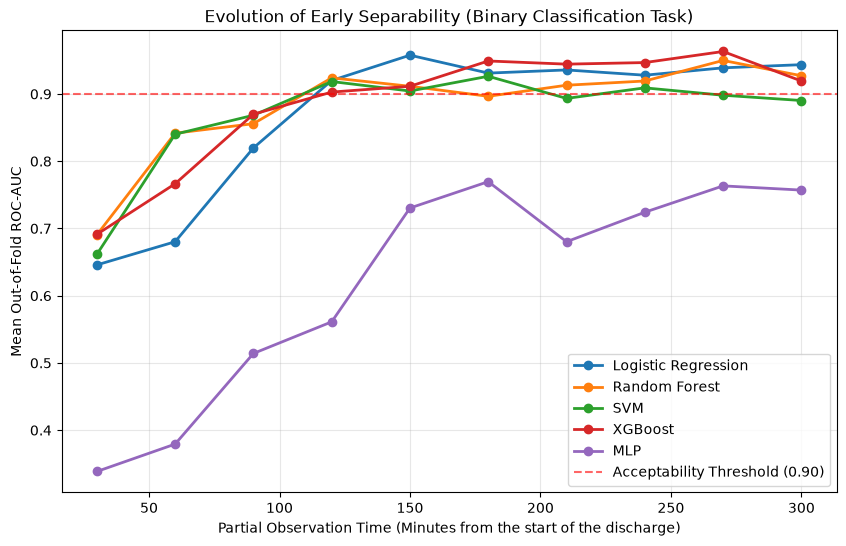

In [10]:
plot_roc_auc_over_time(history, END_WINDOW_TEST)

# Window time choice

Based on the ROC-AUC results, the [90/120] window is chosen as a good compromise between early prediction and model reliability. The ROC-AUC curve shows that the predictive information accumulates over time, and the [90/120] window captures most of the relevant features while still allowing for a significant reduction in test duration compared to the full 14-hour discharge cycle, providing a practical solution for the battery testing lab.


# Hyperparameter Tuning

The previous chapter illustrated how to design, train and evaluate different models, but to increase the goodness of the models, hyperparameter tuning is needed. The hyperparameter tuning is done with a GridSearchCV on the [90/120] window, which was chosen as a good compromise between early prediction and model reliability. The GridSearchCV uses a 3-fold StratifiedGroupKFold CV inside a StandardScaler + Classifier pipeline for each model. The output is one out-of-fold ROC-AUC per (model, hyperparameter) pair, using the best hyperparameters for each model. The goal of this phase is to find the best hyperparameters for each model, which will be used in the final evaluation on the Test set.

In [11]:

START_WINDOW = 90
END_WINDOW = 120

exclude_cols = {'label', 'file_name', 'start_time', 'end_time'}

# Trining Matrix Construction for Hyperparameter Tuning
train_records = []
for file_name in file_train_val:
    df_bat = battery_dict[file_name]
    label = summary_train_df[summary_train_df['file_name'] == file_name]['label'].values[0]
    feat = extract_features_from_battery(df_bat, window_minutes=END_WINDOW, starting_minute=START_WINDOW)
    if feat is not None and not np.isnan(feat['delta_voltage']):
        feat['file_name'] = file_name
        feat['label'] = label
        train_records.append(feat)
        
df_tuning = pd.DataFrame(train_records).bfill().ffill()
feature_names = [c for c in df_tuning.columns if c not in exclude_cols]

X_train = df_tuning[feature_names].values
y_train = df_tuning['label'].values
groups_train = df_tuning['file_name'].values

# Definition of parameter grids for hyperparameter tuning for each model
param_grids = {
    "Logistic Regression": {
        'clf__C': [0.01, 0.1, 1.0, 10.0],
        'clf__l1_ratio': [0.0, 1.0]
    },
    "Random Forest": {
        'clf__n_estimators': [50, 100, 200],
        'clf__max_depth': [4, 6, 8, 12],
        'clf__min_samples_split': [2, 5]
    },
    "SVM": {
        'clf__estimator__C': [0.1, 1.0, 10.0],
        'clf__estimator__kernel': ['linear', 'rbf'],
        'clf__estimator__gamma': ['scale', 'auto']
    },
    "XGBoost": {
        'clf__n_estimators': [50, 100, 150],
        'clf__max_depth': [3, 4, 6],
        'clf__learning_rate': [0.01, 0.05, 0.1]
    },
    "MLP": {
        'clf__hidden_layer_sizes': [(32, 16), (64, 32), (64, 64)],
        'clf__alpha': [0.001, 0.01, 0.1]
    }
}

modelli_ottimizzati = {}

# Optimization cycle for each model using StratifiedGroupKFold and GridSearchCV
sgkf = StratifiedGroupKFold(n_splits=5)

for name, model_instance in models.items():   
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', model_instance)
    ])
    
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=sgkf,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=1
    )
    
    # Fit execution with explicit group handling to ensure proper cross-validation
    grid_search.fit(X_train, y_train, groups=groups_train)
    
    # The best model is saved and is already retrained on the entire training set with
    # the optimal parameters
    modelli_ottimizzati[name] = grid_search.best_estimator_

optimized_results = evaluate_models(
    models=modelli_ottimizzati,
    window_start=START_WINDOW_TEST,
    window_end=END_WINDOW_TEST,
    battery_dict=battery_dict,
    summary_train_df=summary_train_df,
    file_train_val=file_train_val
)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits


c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Fitting 5 folds for each of 9 candidates, totalling 45 fits


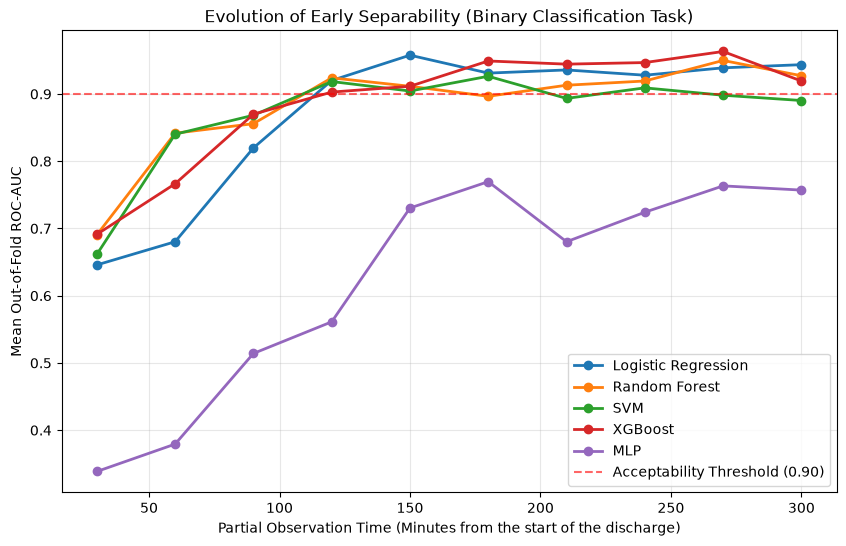

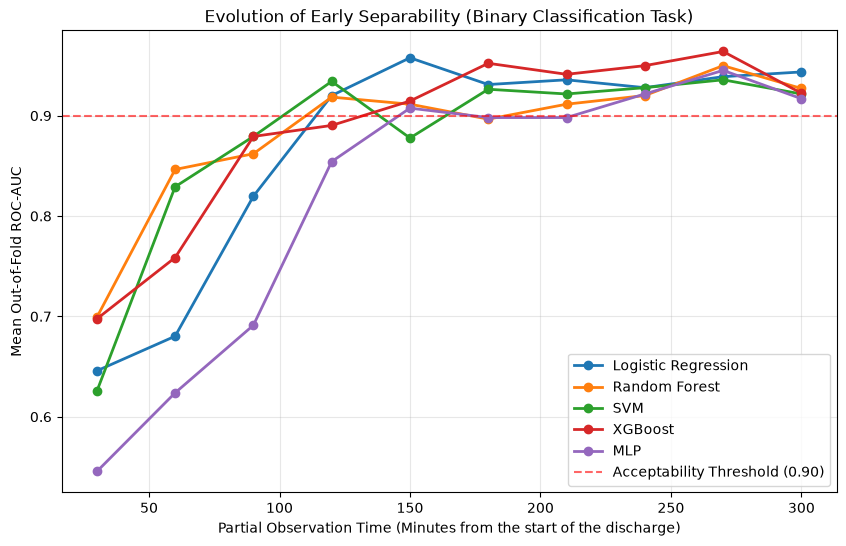

In [12]:
plot_roc_auc_over_time(history, END_WINDOW_TEST)
plot_roc_auc_over_time(optimized_results, END_WINDOW_TEST)

In [13]:
def plot_learning_curve(
        models_to_analyze,
        X_train,
        y_train,
        groups_train):
    """
    Plot learning curves for the given models.

    Parameters:
        models_to_analyze (dict): Dictionary of models to analyze.
        X_train (array-like): Training features.
        y_train (array-like): Training labels.
        groups_train (array-like): Group labels for the training data.
    """
    for model_name, model_to_analyze in models_to_analyze.items():
        sgkf = StratifiedGroupKFold(n_splits=3)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", FitFailedWarning)
            warnings.simplefilter("ignore", RuntimeWarning)
            train_sizes, train_scores, test_scores = learning_curve(
                estimator=model_to_analyze,
                X=X_train,
                y=y_train,
                groups=groups_train,
                train_sizes=np.linspace(0.2, 1.0, 5),
                cv=sgkf,
                scoring='roc_auc',
                n_jobs=-1,
                random_state=RANDOM_SEED
            )
            train_mean = np.nanmean(train_scores, axis=1)
            train_std = np.nanstd(train_scores, axis=1)
            test_mean = np.nanmean(test_scores, axis=1)
            test_std = np.nanstd(test_scores, axis=1)

        plt.figure(figsize=(10, 6))
        plt.plot(train_sizes, train_mean, color='blue', marker='o', markersize=5, label='Training ROC-AUC')
        plt.fill_between(train_sizes, train_mean + train_std, train_mean - train_std, alpha=0.15, color='blue')

        plt.plot(train_sizes, test_mean, color='green', linestyle='--', marker='s', markersize=5, label='Validation ROC-AUC (CV)')
        plt.fill_between(train_sizes, test_mean + test_std, test_mean - test_std, alpha=0.15, color='green')

        plt.title("Learning Curves - Model: {}".format(model_name))
        plt.xlabel("Number of samples (Batteries) used in Training")
        plt.ylabel("ROC-AUC Score")
        plt.grid(True, alpha=0.3)
        plt.legend(loc='lower right')
        plt.show()


In [14]:
exclude_cols = {'label', 'file_name', 'start_time', 'end_time'}

# Training set preparation for the established window
train_records = []
for file_name in file_train_val:
    df_bat = battery_dict[file_name]
    label = summary_train_df[summary_train_df['file_name'] == file_name]['label'].values[0]
    
    # Invocation of the native method to extract features from the battery data within the specified time window
    feat = extract_features_from_battery(df_bat, window_minutes=END_WINDOW, starting_minute=START_WINDOW)
    if feat is not None and not np.isnan(feat['delta_voltage']):
        feat['label'] = label
        train_records.append(feat)
        
df_train_final = pd.DataFrame(train_records).bfill().ffill()
feature_names = [c for c in df_train_final.columns if c not in exclude_cols]

X_train_f = df_train_final[feature_names].values
y_train_f = df_train_final['label'].values

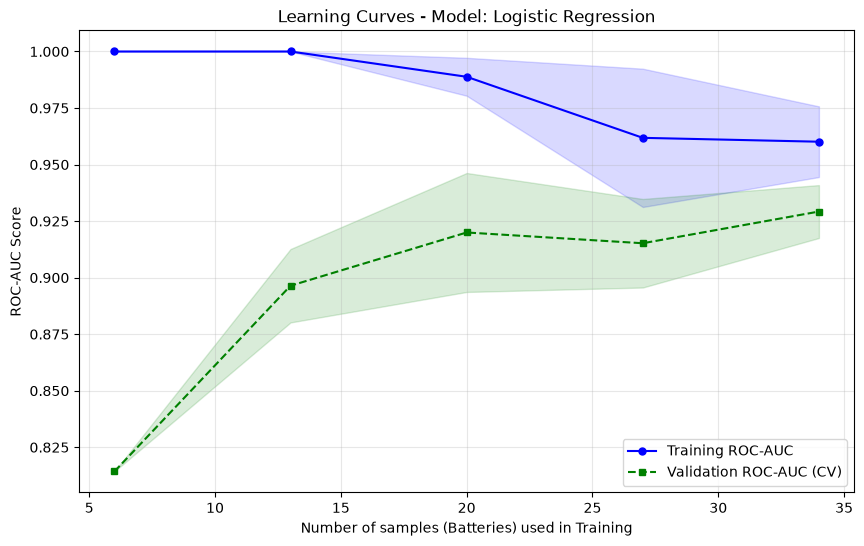

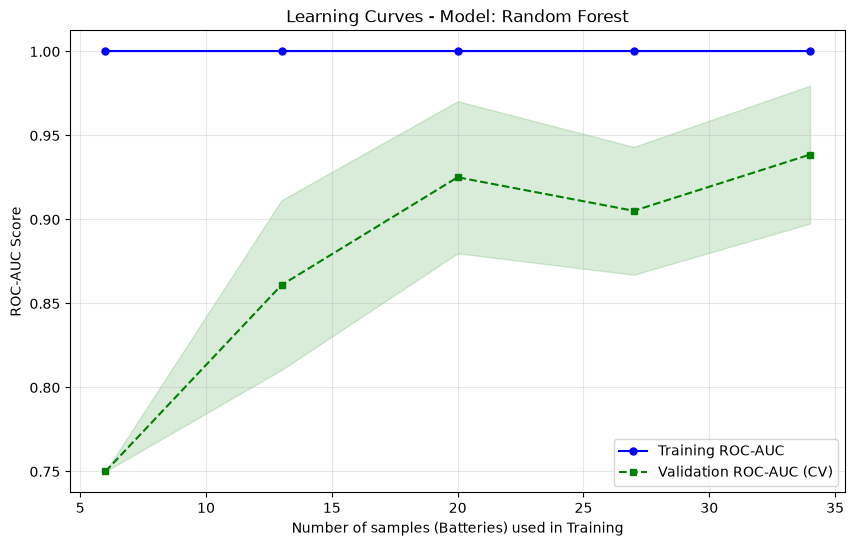

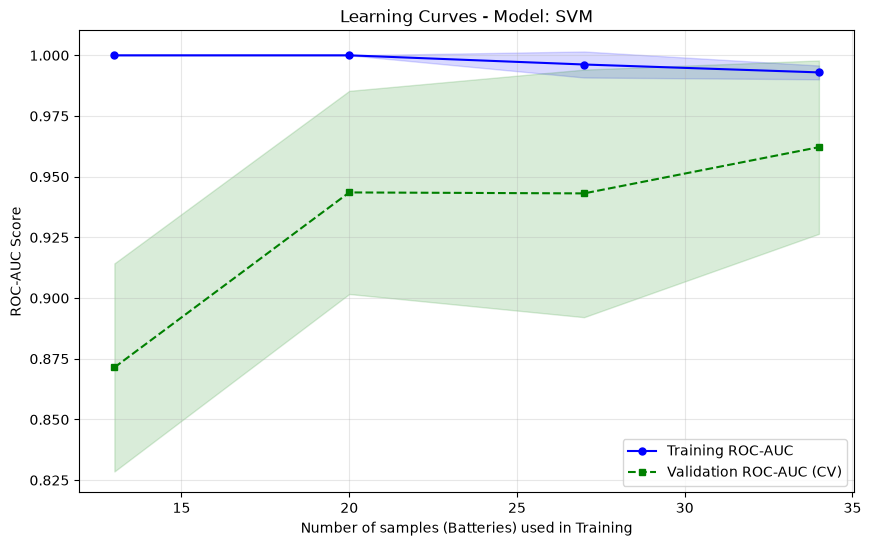

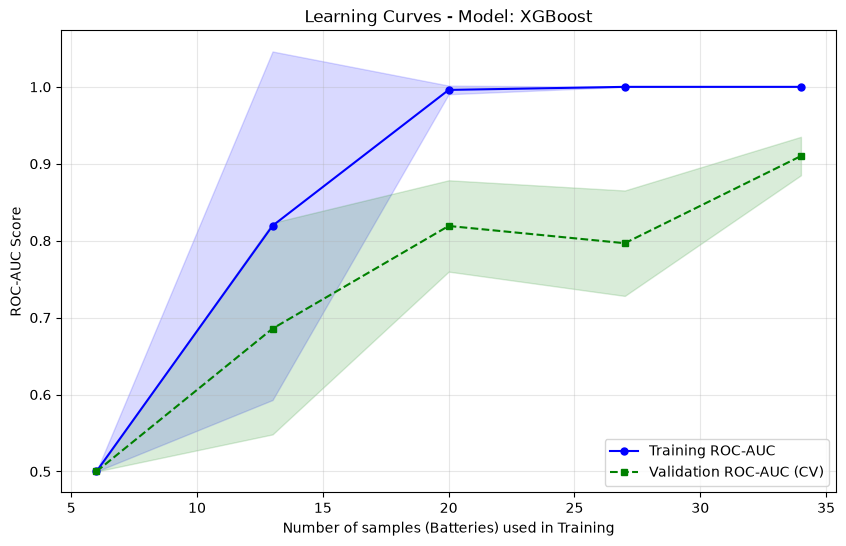

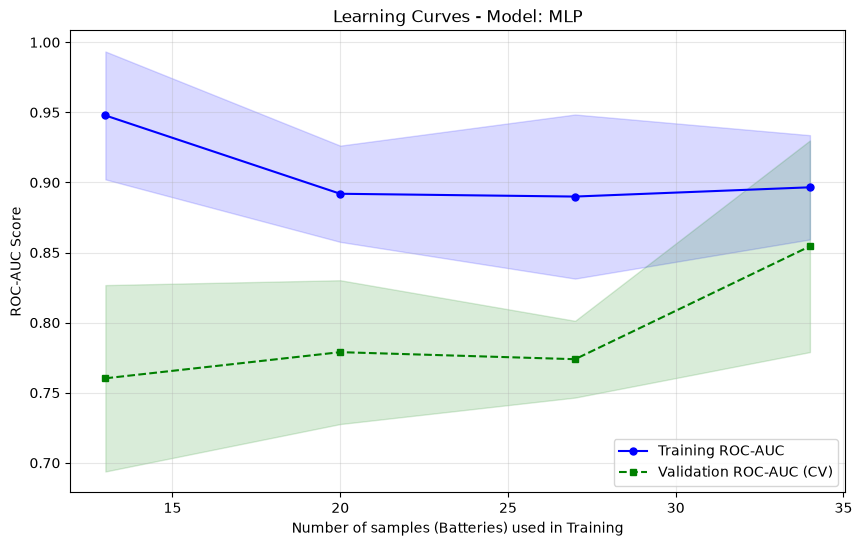

In [15]:
plot_learning_curve(
    models_to_analyze=modelli_ottimizzati,
    X_train=X_train_f,
    y_train=y_train_f,
    groups_train=groups_train
)

### Learning Curves, Overfitting Check

The learning curves show ROC-AUC (train vs. CV validation) as a function of training set size, using StratifiedGroupKFold(3).

- **Large train-val gap**: the model overfits. With ~60–80 total files (80% for training), this is a real risk for high-capacity models like XGBoost and MLP.
- **Both curves flat and low**: underfitting, the model lacks capacity to capture discharge dynamics from these 12 features.
- **Shaded bands**: ±1 std across folds. Wide bands indicate high sensitivity to which files end up in each fold, a consequence of the small dataset.

The overfitting observed here for some models motivates the regularization strategies used in both the classical ML pipeline (L2, balanced class weights) and the deep learning section (Dropout, weight decay, augmentation).

### ROC-AUC over Time: Baseline vs. Tuned

From the two plots, it is possible to see how, the hyperparameter tuning improves the ROC-AUC of the models, especially for the MLP, which was really far from the other models before and now is comparable with the other.

Based on this plot the final window choice is confirmed to be [90/120] minutes, as it captures most of the predictive information while still allowing for a significant reduction in test duration compared to the full 14-hour discharge cycle. This window provides a practical solution for the battery testing lab, balancing early prediction with model reliability.

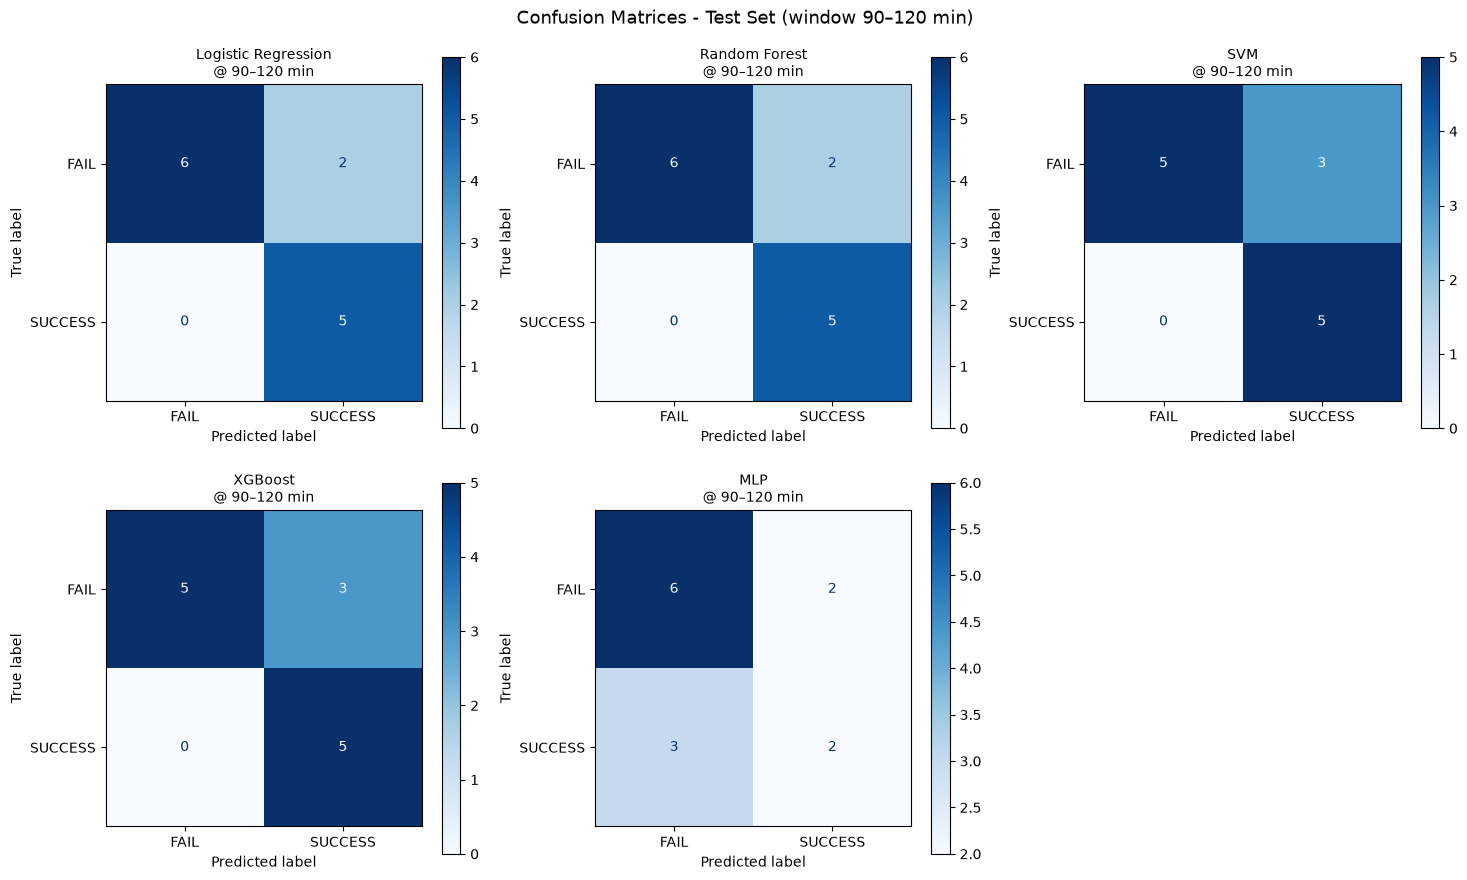

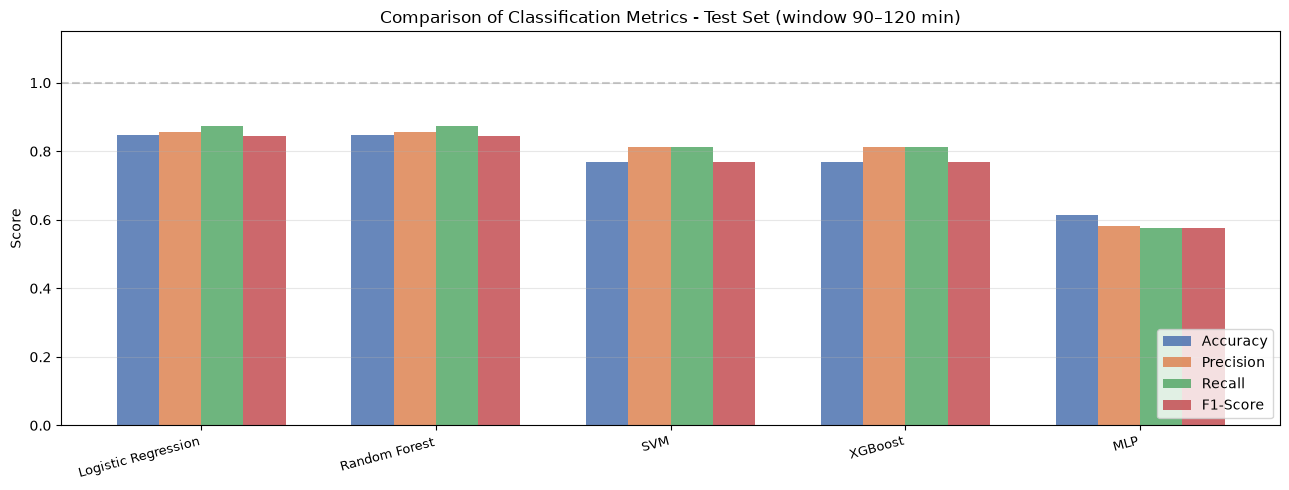

In [16]:
# Test set preparation for the established window
test_records = []
for file_name in file_Test_test:
    df_bat = battery_dict[file_name]
    label = summary_test_df[summary_test_df['file_name'] == file_name]['label'].values[0]
    feat = extract_features_from_battery(df_bat, window_minutes=END_WINDOW, starting_minute=START_WINDOW)
    if feat is not None and not np.isnan(feat['delta_voltage']):
        feat['label'] = label
        test_records.append(feat)

df_test_final = pd.DataFrame(test_records).bfill().ffill()
X_test_f = df_test_final[feature_names].values
y_test_f = df_test_final['label'].values

# Fit, predict and collect metrics for all models
all_predictions = {}
all_metrics = {}

for name, model_instance in modelli_ottimizzati.items():
    model_pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', model_instance)
    ])
    model_pipeline.fit(X_train_f, y_train_f)
    y_pred_f = model_pipeline.predict(X_test_f)

    all_predictions[name] = y_pred_f

    report = classification_report(y_test_f, y_pred_f, target_names=['FAIL', 'SUCCESS'], output_dict=True)
    all_metrics[name] = {
        'Accuracy':  report['accuracy'],
        'Precision': report['macro avg']['precision'],
        'Recall':    report['macro avg']['recall'],
        'F1-Score':  report['macro avg']['f1-score'],
    }

# Grid layout for confusion matrices visualization
model_names = list(modelli_ottimizzati.keys())
n_cols, n_rows = 3, 2

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 9))
for idx, name in enumerate(model_names):
    cm = confusion_matrix(y_test_f, all_predictions[name])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['FAIL', 'SUCCESS'])
    disp.plot(cmap=plt.cm.Blues, ax=axes.flat[idx], values_format='d')
    axes.flat[idx].set_title(f"{name}\n@ {START_WINDOW}–{END_WINDOW} min", fontsize=10)

for idx in range(len(model_names), n_rows * n_cols):
    axes.flat[idx].set_visible(False)

plt.suptitle(f"Confusion Matrices - Test Set (window {START_WINDOW}–{END_WINDOW} min)", fontsize=13)
plt.tight_layout()
plt.show()

# Comparative chart of the main classification metrics for all models on the test set
metrics_df = pd.DataFrame(all_metrics).T
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

x = np.arange(len(model_names))
width = 0.18

fig, ax = plt.subplots(figsize=(13, 5))
for i, (metric, color) in enumerate(zip(metrics_to_plot, colors)):
    ax.bar(x + i * width, metrics_df[metric], width, label=metric, color=color, alpha=0.85)

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(model_names, rotation=15, ha='right', fontsize=9)
ax.set_ylabel('Score')
ax.set_ylim(0, 1.15)
ax.set_title(f'Comparison of Classification Metrics - Test Set (window {START_WINDOW}–{END_WINDOW} min)')
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.4)
ax.legend(loc='lower right')
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


### Final Classification Results on Test Set

Test Set shows a good behaviour from the machine learning models, with a common pattern: a precision of 1.00 on the FAIL class, while having a lower precision on the PASS class. Given the fact that the data foundation isn't big, this is a good result, that could be improved with more data.

It is also possible to see that the MLP model, instead, is not showing a good behaviour, with the worst precision on the PASS class. Should be noticed that MLP model is a deep learning model, which usally needs more data to generalize well, and this dataset is not big enough for this model to perform well.

### Binary Classification Conclusion

The binary classification task shows that the models are able to predict the PASS/FAIL outcome of the battery cells with good accuracy, especially for the FAIL class. The hyperparameter tuning improved the performance of the models, especially for the MLP model, which was far from the other models before tuning. The final window choice of [90/120] minutes is confirmed to be a good compromise between early prediction and model reliability.

To improve the performance of the models, especially for the MLP model, more data is needed, it is possible to assert this because all the main aspects that could lead to an improvement of the models have been already explored, like feature engineering, hyperparameter tuning and model selection.

This section concludes that, for this particular task, whith the amount of data available, the best models are Logistic Regression and Random Forest, this outcome confirms the ability of these two models to generalize well even with a small dataset, while the other models, especially the MLP, need more data to generalize well. The next section will focus on the regression task, which aims to predict the continuous capacity of the battery cells, and will explore different models and techniques to improve the performance of the regression task.


# Early Regression (Continuous Capacity Estimation)


## Regression with Machine Learning Models

Instead of a binary label, the goal of this task is to predict $C_{\mathrm{final}}$ directly as a continuous value. This task will be exploied in two different ways: in the first part, classical machine learning models will be used, while in the second part deep learning models will be used. 

The goal is to compare the performance of the two approaches and to find the best model for this task.

### Expectations

In the previous chapter an outcome from the final test phase was that the data foundation isn't big enough for deep learning models to generalize well, so it is expected that classical machine learning models will perform better than deep learning models in this task. A final section of this task will be in fact dedicated to try to mitigate this problem by applying data augmentation techniques to the deep learning models, in order to increase the amount of data available for training and improve the generalization of the models.

### Feature Design: Lagged Blocks

For regression different extraction strategy has been used. The history before a cut-off has been splitted $t_{\text{end}}$ into $L = 4$ backward-looking blocks of width $\Delta t = 20$ min:

$$\text{Block}_k = [t_{\text{end}} - (k+1) \cdot 20,\;\; t_{\text{end}} - k \cdot 20], \quad k = 0, 1, 2, 3$$

Each block contributes 7 features: $\dot{V}$, $\bar{V}$, $\sigma_V$, $\dot{C}$, $V_{\text{start}}$, $V_{\text{end}}$, $C_{\text{end}}$. Total: $4 \times 7 = 28$ features, labelled with suffixes _t, _t-1, _t-2, _t-3.

The rationale: the trajectory of these 7 descriptors over the 4 most recent 20-minute blocks encodes temporal dynamics, how the voltage slope and capacity rate are evolving, which a single-window aggregate would miss.

**The lagged features extraction** function extract_regression_lagged_features implements this strategy, aggregating the data into backward-looking blocks and computing the relevant features for each block. Aggregated features is a common strategy in time series regression, as it allows the model to capture temporal dependencies and trends in the data, which are often crucial for accurate predictions.


In [17]:
MINUTO_FINE_OSSERVAZIONE = 400
BLOCK_WIDTH_MINUTES = 20
LAG_STEPS_COUNT = 4  

COLONNA_TARGET_Y = 'final_capacity' 

def extract_regression_lagged_features(df, base_window_min=10, steps=3, end_minute=90):
    """
    Extract the physical features by aggregating the data into backward time blocks.
    Returns a single flat dictionary with lagged features (_t, _t-1, _t-2, _t-3).
    1. dv_dt: slope of the voltage
    2. mean_voltage: average voltage
    3. std_voltage: standard deviation of the voltage
    4. dC_dt: slope of the capacity
    5. voltage_start: starting voltage of the block
    6. voltage_end: ending voltage of the block
    7. capacity_end: ending capacity of the block
    """
    all_features = {}
    
    for step in range(steps):
        # Calculation of the temporal boundaries of the current block
        w_start = end_minute - (step + 1) * base_window_min
        w_end = end_minute - step * base_window_min
        
        if w_start < 0:
            break
            
        # Subset temporal filtering of the single battery test CSV
        truncated_df = df[(df['elapsed_min'] >= w_start) & (df['elapsed_min'] <= w_end)]
        
        # Security check if there are missing records in the block
        if len(truncated_df) < 2:
            return None 
            
        # Calculus of physical slopes and averages over the block
        delta_voltage = truncated_df['Tensione (V)'].iloc[-1] - truncated_df['Tensione (V)'].iloc[0]
        dv_dt = delta_voltage / base_window_min
        v_mean = truncated_df['Tensione (V)'].mean()
        v_std = truncated_df['Tensione (V)'].std()
        
        delta_C = truncated_df['Capacity (Ah)'].iloc[0] - truncated_df['Capacity (Ah)'].iloc[-1]
        dC_dt = delta_C / base_window_min
        
        v_start = truncated_df['Tensione (V)'].iloc[0]
        v_end = truncated_df['Tensione (V)'].iloc[-1]
        c_end = truncated_df['Capacity (Ah)'].iloc[-1]
        
        # Indentification suffix for lagged features
        suffix = f"_t" if step == 0 else f"_t-{step}"
        
        # Feature mapping with suffixes for lagged features
        all_features[f'dv_dt{suffix}'] = dv_dt
        all_features[f'mean_voltage{suffix}'] = v_mean
        all_features[f'std_voltage{suffix}'] = v_std
        all_features[f'dC_dt{suffix}'] = dC_dt
        all_features[f'voltage_start{suffix}'] = v_start
        all_features[f'voltage_end{suffix}'] = v_end
        all_features[f'capacity_end{suffix}'] = c_end

    return all_features

# Train / Validation Set (20% Test test set)
train_regression_records = []
for file_name in file_train_val:
    df_bat = battery_dict[file_name]
    # Recover the value of the continuous target (final capacity) from the summary DataFrame
    y_val = summary_train_df[summary_train_df['file_name'] == file_name][COLONNA_TARGET_Y].values[0]
    
    feat_reg = extract_regression_lagged_features(
        df_bat, base_window_min=BLOCK_WIDTH_MINUTES, steps=LAG_STEPS_COUNT, end_minute=MINUTO_FINE_OSSERVAZIONE
    )
    
    if feat_reg is not None:
        feat_reg['file_name'] = file_name
        feat_reg['target_capacity'] = y_val  # Nuovo target Continuo (Y)
        train_regression_records.append(feat_reg)

df_reg_train = pd.DataFrame(train_regression_records).bfill().ffill()

# extract the same features for the Test test set
test_regression_records = []
for file_name in file_Test_test:
    df_bat = battery_dict[file_name]
    y_val = summary_test_df[summary_test_df['file_name'] == file_name][COLONNA_TARGET_Y].values[0]
    
    feat_reg = extract_regression_lagged_features(
        df_bat, base_window_min=BLOCK_WIDTH_MINUTES, steps=LAG_STEPS_COUNT, end_minute=MINUTO_FINE_OSSERVAZIONE
    )
    
    if feat_reg is not None:
        feat_reg['file_name'] = file_name
        feat_reg['target_capacity'] = y_val
        test_regression_records.append(feat_reg)

df_reg_test = pd.DataFrame(test_regression_records).bfill().ffill()

# Matrix isolation for regression tasks
exclude_reg_cols = {'target_capacity', 'file_name', 'start_time', 'end_time', 'label'}
feature_reg_names = [c for c in df_reg_train.columns if c not in exclude_reg_cols]

X_train_r = df_reg_train[feature_reg_names].values
y_train_r = df_reg_train['target_capacity'].values
groups_train_r = df_reg_train['file_name'].values

X_test_r = df_reg_test[feature_reg_names].values
y_test_r = df_reg_test['target_capacity'].values

### Models definition

In this section, three different models are evaluated for the regression task: Random Forest Regressor, XGBoost Regressor, and Support Vector Regression (SVR). As will be better underline in the next sections, these models differs from their classification counterparts, as they are trained to minimize the mean squared error (MSE) between the predicted and true values, instead of minimizing the binary cross-entropy loss function.

#### Random Forest Regressor
Random Forest Regressor is an ensemble learning method that constructs multiple decision trees during training and outputs the mean prediction of the individual trees. It is robust to overfitting and can handle high-dimensional data. Compared to the Random Forest Classifier, the Random Forest Regressor does not provides a probability output, but instead provides a continuous value as the prediction, this is possible because the model is trained to minimize the mean squared error (MSE) between the predicted and true values. While the Random Forest Classifier is trained to minimize the binary cross-entropy loss function, which is not suitable for regression tasks.

**Minimization of the MSE**: The Random Forest Regressor is trained to minimize the mean squared error (MSE) between the predicted and true values. The MSE is defined as:

$$\text{MSE} = \frac{1}{N} \sum_{i=1}^{N} (C_{\mathrm{final}, i} - \hat{C}_{\mathrm{final}, i})^2$$

Where:
- $N$ is the number of training samples.
- $C_{\mathrm{final}, i}$ is the true value of the $i$-th sample.
- $\hat{C}_{\mathrm{final}, i}$ is the predicted value of the $i$-th sample.

#### XGBoost Regressor
XGBoost Regressor is an optimized implementation of gradient boosting that is designed for speed and performance. It builds an ensemble of decision trees in a sequential manner, where each tree corrects the errors of the previous ones. As for the Random Forest Regressor, the XGBoost Regressor is trained to minimize the mean squared error (MSE) between the predicted and true values, which differs from the XGBoost Classifier, which is trained to minimize the binary cross-entropy loss function.

The **minimization of the MSE** is the same as for the Random Forest Regressor.

#### Support Vector Regression (SVR)
Support Vector Regression (SVR) is a supervised learning algorithm that finds the optimal hyperplane that best fits the data points in a high-dimensional space. The model tries to find a function that deviates from the true values by a value no greater than a specified margin (epsilon), while also being as flat as possible. The SVR model can be used for both linear and non-linear regression tasks, depending on the choice of kernel function. Compared to the Support Vector Machine (SVM) Classifier, the SVR does not provide a probability output, but instead provides a continuous value as the prediction, this is possible because the model is trained to minimize the mean squared error (MSE) between the predicted and true values. While the SVM Classifier is trained to minimize the binary cross-entropy loss function, which is not suitable for regression tasks.

The **minimization of the MSE** is the same as for the Random Forest Regressor.

### Hyperparameter Tuning

In the binary classification task, a first evaluation of the models was done without the hyperparameter tuning. Since it has been proved that this technique improved the performance of the models, it has been decided to be applied to this section suddenly. In this section, after the models definition, the grid parameters for each model are defined, they will be used to perform a GridSearchCV on the training set.

In [18]:
modelli_regressione = {
    "Random Forest Regressor": RandomForestRegressor(random_state=RANDOM_SEED, n_jobs=-1),
    "XGBoost Regressor": XGBRegressor(random_state=RANDOM_SEED, n_jobs=-1, eval_metric='rmse'),
    "Support Vector Regressor (SVR)": SVR()
}

# specific hyperparameter grids for regression tasks
param_grids_regression = {
    "Random Forest Regressor": {
        'clf__n_estimators': [50, 100, 200],
        'clf__max_depth': [4, 6, 8],
        'clf__min_samples_leaf': [1, 3, 5]
    },
    "XGBoost Regressor": {
        'clf__n_estimators': [50, 100, 150],
        'clf__max_depth': [3, 4, 5],
        'clf__learning_rate': [0.01, 0.05, 0.1]
    },
    "Support Vector Regressor (SVR)": {
        'clf__C': [0.1, 1.0, 10.0, 50.0],
        'clf__kernel': ['linear', 'rbf'],
        'clf__gamma': ['scale', 'auto']
    }
}

In [19]:
# Lists to store scores for plotting
nomi_modelli = []
rmse_train_list = []
rmse_val_list = []

def tune_and_diagnose_regression(cut_off_minute, battery_dict, summary_train_df, file_train_val):
    """
    Tune and diagnose regression models for battery capacity prediction.

    Args:
        cut_off_minute (int): The minute at which to cut off the data for feature extraction.
        battery_dict (dict): Dictionary containing battery dataframes keyed by file names.
        summary_train_df (pd.DataFrame): DataFrame containing summary information for training batteries.
        file_train_val (list): List of file names to be used for training and validation.

    Returns:
        tuple: Tuple containing optimized models, feature names, and RMSE scores for training and validation.
    """
    records_tuning = []
    for file_name in file_train_val:
        df_bat = battery_dict[file_name]
        y_val = summary_train_df[summary_train_df['file_name'] == file_name]['final_capacity'].values[0]
        feat_reg = extract_regression_lagged_features(
            df=df_bat, 
            base_window_min=BLOCK_WIDTH_MINUTES, 
            steps=LAG_STEPS_COUNT, 
            end_minute=cut_off_minute)
        if feat_reg is not None:
            feat_reg['file_name'] = file_name
            feat_reg['target_capacity'] = y_val
            records_tuning.append(feat_reg)
            
    df_tuning_r = pd.DataFrame(records_tuning).bfill().ffill()
    exclude_cols = {'target_capacity', 'file_name', 'start_time', 'end_time', 'label'}
    feature_names = [c for c in df_tuning_r.columns if c not in exclude_cols]
    
    X_train = df_tuning_r[feature_names].values
    y_train = df_tuning_r['target_capacity'].values
    groups_train = df_tuning_r['file_name'].values
    
    gkf = GroupKFold(n_splits=5)
    
    modelli_reg_ottimizzati = {}
    rmse_train_list = {}
    rmse_val_list = {}
    
    for idx, (name, model_instance) in enumerate(modelli_regressione.items()):
        pipeline = Pipeline([('scaler', StandardScaler()), ('clf', model_instance)])
        
        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grids_regression[name],
            cv=gkf,
            scoring='neg_mean_squared_error',
            return_train_score=True,
            n_jobs=-1
        )
        grid_search.fit(X_train, y_train, groups=groups_train)
        
        # Combination points extraction for the best hyperparameter combination
        best_index = grid_search.best_index_
        mean_train_neg_mse = grid_search.cv_results_['mean_train_score'][best_index]
        mean_val_neg_mse = grid_search.cv_results_['mean_test_score'][best_index]
        
        # Conversion to positive RMSE (Ah)
        rmse_train = np.sqrt(-mean_train_neg_mse)
        rmse_val = np.sqrt(-mean_val_neg_mse)
        
        # Store the best model and its corresponding RMSE scores
        modelli_reg_ottimizzati[name] = grid_search.best_estimator_
        rmse_train_list[name] = rmse_train
        rmse_val_list[name] = rmse_val

    
    return modelli_reg_ottimizzati, feature_names, rmse_train_list, rmse_val_list

### Hyperparameter Tuning over Time: [60, 90, 120, 150] minutes

The hyperparameter tuning is performed over 4 different time windows: [60, 90, 120, 150] minutes. The goal is to find the best combination between the time window and the hyperparameters for each model, in order to find the best model for this task.

### Time Window Choice

As introduced in the previous section, the time window choice is a trade-off between early prediction and model reliability. The ROC-AUC curve shows that the predictive information accumulates over time, the final time window choice, for each model, will be made by the code itself, based on an heuristic that takes into account the MSE and the MAE of each model, in order to find the best compromise between early prediction and model reliability. The final time window choice will be used for the final evaluation on the Test set. The expectation is that, for a task with a limited amount of data, the best window choice will be the last one, as it contains the most information about the discharge curve, and this is confirmed by the results in the cell above.

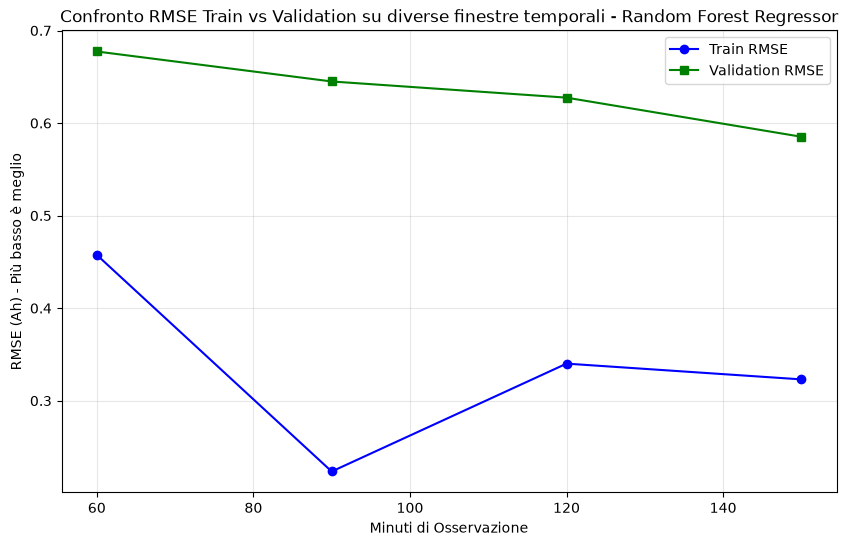

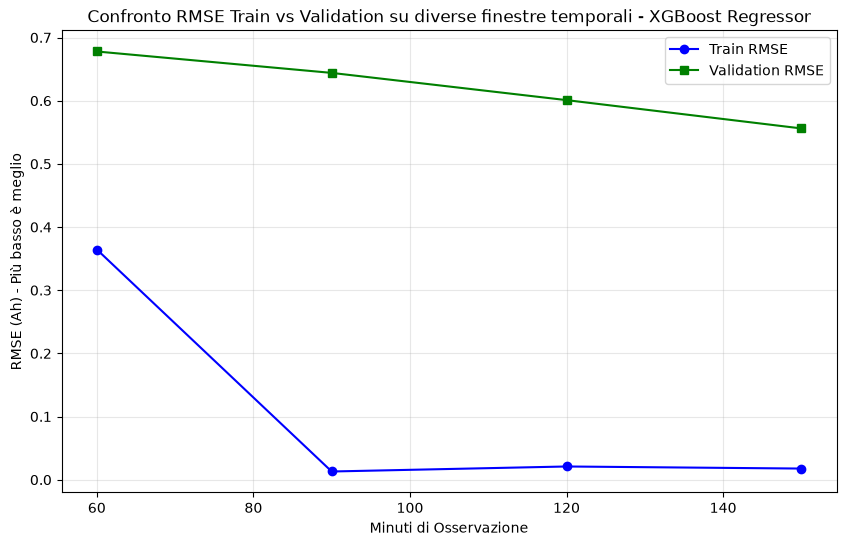

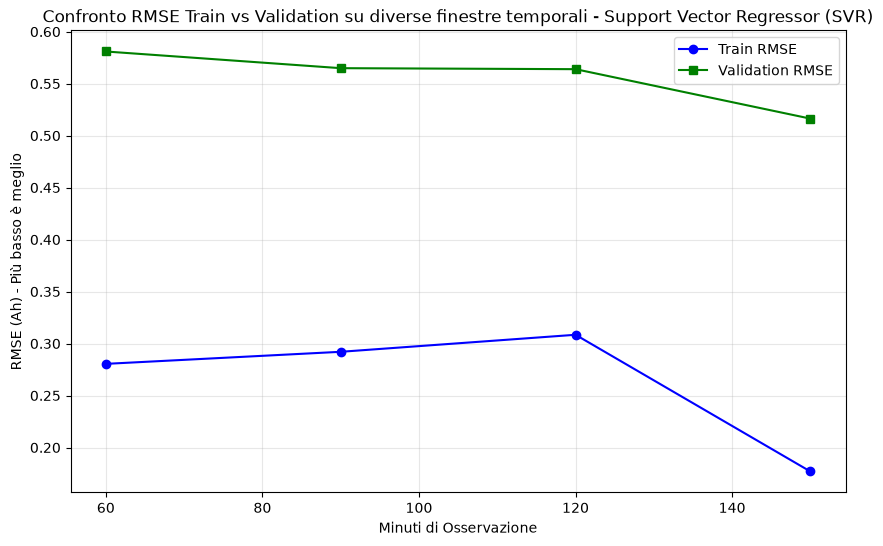

=== Random Forest Regressor ===
 -> Minimum absolute RMSE: 0.585 Ah
 -> Optimal observation window (with compromise): 150 minutes (RMSE: 0.585 Ah)

=== XGBoost Regressor ===
 -> Minimum absolute RMSE: 0.556 Ah
 -> Optimal observation window (with compromise): 150 minutes (RMSE: 0.556 Ah)

=== Support Vector Regressor (SVR) ===
 -> Minimum absolute RMSE: 0.516 Ah
 -> Optimal observation window (with compromise): 150 minutes (RMSE: 0.516 Ah)



In [20]:
ARR_MINUTES_OBSERVATION = [60,90,120,150]
TOLLERANCE_AH = 0.025 

rmse_train_list = []
rmse_val_list = []
modelli_reg_ottimi_list = []
feature_reg_selezionate_list = []
for timespan in ARR_MINUTES_OBSERVATION:
    modelli_reg_ottimi_tmp, feature_reg_selezionate_tmp, rmse_train_list_tmp, rmse_val_list_tmp = tune_and_diagnose_regression(
        cut_off_minute=timespan,
        battery_dict=battery_dict,
        summary_train_df=summary_train_df,
        file_train_val=file_train_val
    )
    rmse_train_list.append(rmse_train_list_tmp)
    rmse_val_list.append(rmse_val_list_tmp)
    modelli_reg_ottimi_list.append(modelli_reg_ottimi_tmp)
    feature_reg_selezionate_list.append(feature_reg_selezionate_tmp)

# Compare the RMSE values across different observation windows
# this should be done for each model
for model_name in modelli_regressione.keys():
    train_rmse = [rmse_train[model_name] for rmse_train in rmse_train_list]
    val_rmse = [rmse_val[model_name] for rmse_val in rmse_val_list]
    plt.figure(figsize=(10, 6))
    plt.plot(ARR_MINUTES_OBSERVATION, train_rmse, marker='o', label='Train RMSE', color='blue')
    plt.plot(ARR_MINUTES_OBSERVATION, val_rmse, marker='s', label='Validation RMSE', color='green')
    plt.title(f"Confronto RMSE Train vs Validation su diverse finestre temporali - {model_name}")
    plt.xlabel("Minuti di Osservazione")
    plt.ylabel("RMSE (Ah) - Più basso è meglio")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

# Choose one of the observation windows based on the RMSE comparison for final testing
# The window should be the one with the lowest validation RMSE and acceptable
# train RMSE (to avoid overfitting) best_index = {}
final_regression_model = {}
final_feature_names = {}

best_index = {}
for model_name in modelli_regressione.keys():
    # Extracts the list of validation RMSE for the current model
    val_rmse_vettore = [rmse_val[model_name] for rmse_val in rmse_val_list]
    
    # Find the absolute minimum
    absolute_min_val_rmse = np.min(val_rmse_vettore)
    
    # Finds all the indexes where the error is close to the minimum within the tolerance
    indici_accettabili = np.where(val_rmse_vettore <= (absolute_min_val_rmse + TOLLERANCE_AH))[0]
    
    # Between the acceptable indices, we take the FIRST one (i.e., the shortest/earliest time window)
    best_index[model_name] = indici_accettabili[0]
    
    best_observation_window = ARR_MINUTES_OBSERVATION[best_index[model_name]]
    rmse_choose = val_rmse_vettore[best_index[model_name]]
    
    print(f"=== {model_name} ===")
    print(f" -> Minimum absolute RMSE: {absolute_min_val_rmse:.3f} Ah")
    print(f" -> Optimal observation window (with compromise): {best_observation_window} minutes (RMSE: {rmse_choose:.3f} Ah)\n")

for model_name, index in best_index.items():
    final_regression_model[model_name] = modelli_reg_ottimi_list[index][model_name]
    final_feature_names[model_name] = feature_reg_selezionate_list[index]

### Model predictions on Test Set

#### Metrics

Metrics used to evaluate the performance of the models on the test set are:

- **Mean Absolute Error (MAE)**: average error in Ah, the lower the better, directly interpretable operationally:
$$\text{MAE} = \frac{1}{N} \sum_{i=1}^{N} |C_{\mathrm{final}, i} - \hat{C}_{\mathrm{final}, i}|$$
- **$R^2$ (Coefficient of Determination)**: fraction of capacity variance explained by the model, the higher the better, the best possible score is 1.0, and it can be negative (because the model can be arbitrarily worse). An $R^2$ of 0.0 means that the model does not explain any of the variance in the target variable, while an $R^2$ of 1.0 means that the model perfectly explains all of the variance in the target variable.
$$R^2 = 1 - \frac{\sum_{i=1}^{N} (C_{\mathrm{final}, i} - \hat{C}_{\mathrm{final}, i})^2}{\sum_{i=1}^{N} (C_{\mathrm{final}, i} - \bar{C}_{\mathrm{final}})^2}$$

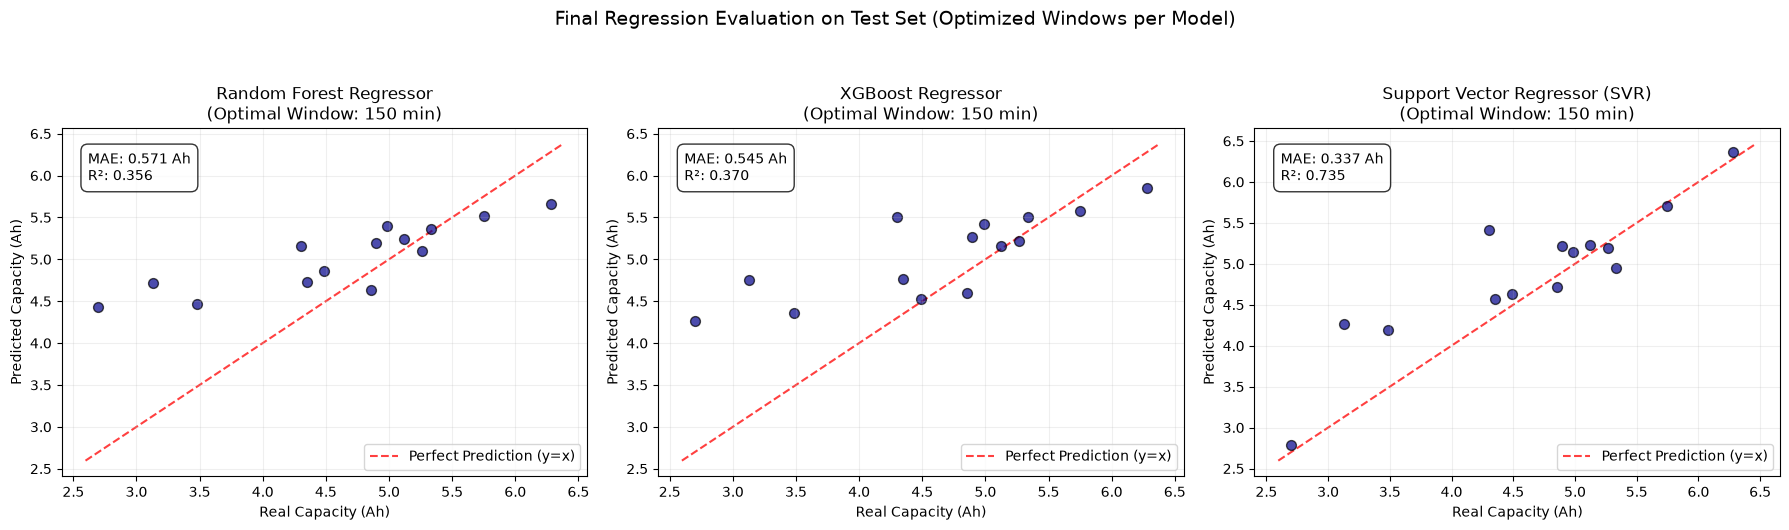

In [21]:
# Prediction and plotting of True vs Predicted (Initialize the figure before the loop)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Cycle robustly through each model independently
for idx, (name, pipeline_ottima) in enumerate(final_regression_model.items()):
    
    model_best_window = ARR_MINUTES_OBSERVATION[best_index[name]]
    model_feature_names = final_feature_names[name]
    
    # Test Matrix Construction for the specific model's optimal window
    test_regression_records = []
    for file_name in file_Test_test:
        df_bat = battery_dict[file_name]
        y_val = summary_test_df[summary_test_df['file_name'] == file_name]['final_capacity'].values[0]
        
        # Extract historical features using the optimal cut-off for the current model
        base_w = BLOCK_WIDTH_MINUTES
        n_steps = LAG_STEPS_COUNT
        
        feat_reg = extract_regression_lagged_features(
            df_bat, base_window_min=base_w, steps=n_steps, end_minute=model_best_window
        )
        
        if feat_reg is not None:
            feat_reg['file_name'] = file_name
            feat_reg['target_capacity'] = y_val
            test_regression_records.append(feat_reg)
            
    '''    
    if not test_regression_records:
        print(f"Impossibile estrarre dati di test per {name} alla finestra {model_best_window} min.")
        continue
    '''
        
    df_reg_test = pd.DataFrame(test_regression_records).bfill().ffill()
    
    X_test_r = df_reg_test[model_feature_names].values
    y_test_r = df_reg_test['target_capacity'].values
    
    # The model is already trained and configured, we make the prediction
    y_pred_r = pipeline_ottima.predict(X_test_r)
    
    # Calculation of the metrics for the current model on the test set
    mae = mean_absolute_error(y_test_r, y_pred_r)
    r2 = r2_score(y_test_r, y_pred_r)
    
    # Plot the chart of True vs Predicted for the current model
    ax = axes[idx]
    ax.scatter(y_test_r, y_pred_r, color='darkblue', alpha=0.7, edgecolors='k', s=50)
    
    # Reference line for perfect prediction (y=x)
    lims = [min(y_test_r.min(), y_pred_r.min()) - 0.1, max(y_test_r.max(), y_pred_r.max()) + 0.1]
    ax.plot(lims, lims, 'r--', alpha=0.75, zorder=0, label="Perfect Prediction (y=x)")
    
    ax.set_title(f"{name}\n(Optimal Window: {model_best_window} min)")
    ax.set_xlabel("Real Capacity (Ah)")
    ax.set_ylabel("Predicted Capacity (Ah)")
    ax.grid(True, alpha=0.2)
    ax.text(0.05, 0.85, f"MAE: {mae:.3f} Ah\nR²: {r2:.3f}", 
            transform=ax.transAxes, bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
    ax.legend(loc='lower right')

plt.suptitle("Final Regression Evaluation on Test Set (Optimized Windows per Model)", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

#### Results

Each scatter plot shows true vs. predicted capacity on the Test set for one model at its optimal cut-off window. Points on the 45° diagonal are perfect predictions.

The final evaluation on the test set shows a good behaviour of the SVR, which, with a MAE of 0.3 and a $R^2$ score of 0.735, demonstrates a strong predictive capability, while the other models, Random Forest and XGBoost, show a lower performance, with a MAE of 0.5 and a $R^2$ score of 0.5 for the Random Forest, and a MAE of 0.6 and a $R^2$ score of 0.4 for the XGBoost.

Especially, it needs to be noticed that, the SVR model, is the only one able to make a prediction below 4.0 Ah, demostrating a good generalization capability, while the other models are not able to make a prediction below 4.0 Ah, which is a clear sign of lack in generalization capability, due also to a small amount of data available for training, especially for tests with a final capacity lower than 4.0 Ah, which are not so frequent.


# Deep Learning Models

In [22]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input, Conv1D, GlobalAveragePooling1D, LeakyReLU, MaxPooling1D, Flatten
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import StratifiedShuffleSplit


### Deep Learning Approach

The classical ML pipelines compute 12–28 scalar features per window. That compresses the signal into a handful of statistics and throws away the temporal shape of the curve.

The deep learning approach, instead, feeds the raw multivariate time series into a neural network. The network can learn its own features from the data, potentially discovering patterns that are invisible to hand-crafted statistics. Compared to the classical ML models, it is crucial to feed the network with data that really carry information. A physical dimension that is, for the most of the time, flat, will feed noise and poor data into the network, resulting in poor generalization.

To solve this task with a deep learning approach, two different architectures are evaluated: LSTM and 1D-CNN. Both architectures are designed to handle sequential data, but they have different strengths and weaknesses.

1. **LSTM**: reads the sequence step by step via gated recurrence. The forget/input/output gates can in principle capture cumulative discharge history. In practice, LSTMs need more training samples than CNNs to generalize, which is a known limitation at this dataset size.
2. **1D-CNN**: two convolutional blocks scan the time axis for local patterns (e.g., the onset of the voltage knee, a change in $\dot{V}$ slope). More parameter-efficient than LSTM on short sequences.

Both models receive a 4-channel input ($V$, $C$, $\dot{V}$, $\dot{C}$). The derivative channels $\dot{V}$ and $\dot{C}$ give the networks the same kinematic information that has been computed manually in the classical ML features, the difference is that here the network learns end-to-end how to weight them.

In [ ]:

# Costruisce summary_df dai CSV grezzi (valori non ricampionati) per il Deep Learning
records = []
for file in sorted(os.listdir(RAW_CSV_FOLDER)):
    if file.endswith(".csv"):
        df_raw = pd.read_csv(os.path.join(RAW_CSV_FOLDER, file), sep=';')
        final_capacity = float(df_raw['Capacity (Ah)'].iloc[-1])
        records.append({'file_name': file, 'final_capacity': final_capacity})

summary_df = pd.DataFrame(records)
# Manteniamo solo le batterie presenti in battery_dict (quelle effettivamente caricate)
summary_df = summary_df[summary_df['file_name'].isin(battery_dict.keys())].reset_index(drop=True)
print(f"summary_df built: {len(summary_df)} batteries, final_capacity dtype: {summary_df['final_capacity'].dtype}")


✓ summary_df built: 66 batteries, final_capacity dtype: float64


### Stratified Split for Deep Learning

To assure a clean dataset summary_df has been rebuilt from the raw CSVs and the train/Test split has been performed using StratifiedShuffleSplit. The previous random split from the binary classification task is replaced because on ~70 files a purely random 80/20 split can accidentally concentrate all degraded cells in one partition.

To improve the learning phase of the models,  $C_{\mathrm{final}}$ is discretized into 4 bins, $[0, 3)$, $[3, 4)$, $[4, 5)$, $[5, +\infty)$ Ah, and stratified on them, so both partitions reflect the same degradation distribution.


In [24]:

# 4 categories for stratified split based on final_capacity
bins = [0, 3.0, 4.0, 5.0, np.inf]
labels = [1, 2, 3, 4]

summary_df['capacity_bin'] = pd.cut(summary_df['final_capacity'], bins=bins, labels=labels, include_lowest=True)

# Check for NaN in bins (batteries out of range)
nan_bins = summary_df['capacity_bin'].isna().sum()
if nan_bins > 0:
    print(f"Warning: {nan_bins} batteries out of bins, they will be excluded from the stratified split.")
    summary_df = summary_df.dropna(subset=['capacity_bin']).reset_index(drop=True)

# Configuration of the stratified split to isolate the Test Set (e.g., 20%)
split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

for train_index, test_index in split.split(summary_df, summary_df['capacity_bin']):
    strat_train_set = summary_df.iloc[train_index]
    strat_test_set = summary_df.iloc[test_index]

# Extract file lists for Deep Learning
file_train_val = strat_train_set['file_name'].tolist()
file_test = strat_test_set['file_name'].tolist()

summary_train_df = summary_df[summary_df['file_name'].isin(file_train_val)][['file_name', 'final_capacity']].reset_index(drop=True)
summary_test_df = summary_df[summary_df['file_name'].isin(file_test)][['file_name', 'final_capacity']].reset_index(drop=True)

print(f"Batterie nel Train/Val set: {len(summary_train_df)}")
print(f"Batterie nel Test set: {len(summary_test_df)}")

# Check for anti-leakage
overlap = set(file_train_val).intersection(set(file_test))
assert len(overlap) == 0, "ERROR: Overlap between train and test!"
print("✓ No overlap between train and test (anti-leakage OK)")


Batterie nel Train/Val set: 52
Batterie nel Test set: 14
✓ No overlap between train and test (anti-leakage OK)


In [25]:
def build_sequential_tensor(file_list, battery_dict, summary_df, cut_off_minute=150, resolution_min=1):
    """
    Tensor 3D with 4 channels: V, C, dV/dt, dC/dt.
    - d²V/dt² removed (>70σ of outliers on resampled data).
    - Derivatives calculated on smoothed signal (rolling 5 min) before diff.
    - Clamp physical on both derivatives.
    dC/dt is the most direct physical predictor of final capacity:
    a degraded battery discharges faster from the beginning of the test.

    Args:
        file_list: list of battery file names to process
        battery_dict: dictionary of battery dataframes keyed by file names
        summary_df: dataframe with final capacity for each battery
        cut_off_minute: minute at which to truncate the data for tensor construction
        resolution_min: time resolution in minutes for interpolation
    Returns:
        X_list: list of 3D tensors (batteries x timesteps x channels)
        y_list: list of final capacities corresponding to each battery
        files_in_tensor: list of file names corresponding to each tensor
    """
    X_list = []
    y_list = []
    files_in_tensor = []

    target_timesteps = np.arange(0, cut_off_minute + resolution_min, resolution_min)

    for file_name in file_list:
        df_bat = battery_dict[file_name]
        y_val = summary_df[summary_df['file_name'] == file_name]['final_capacity'].values[0]

        df_truncated = df_bat[df_bat['elapsed_min'] <= cut_off_minute].copy()
        if df_truncated['elapsed_min'].max() < (cut_off_minute - 1):
            continue

        df_truncated['Tensione (V)'] = df_truncated['Tensione (V)'].ffill().bfill()
        df_truncated['Capacity (Ah)'] = df_truncated['Capacity (Ah)'].ffill().bfill()
        df_truncated = df_truncated.sort_values('elapsed_min')

        v_interp = np.interp(target_timesteps, df_truncated['elapsed_min'], df_truncated['Tensione (V)'])
        c_interp = np.interp(target_timesteps, df_truncated['elapsed_min'], df_truncated['Capacity (Ah)'])

        if np.isnan(v_interp).any() or np.isnan(c_interp).any():
            v_interp = pd.Series(v_interp).ffill().bfill().values
            c_interp = pd.Series(c_interp).ffill().bfill().values

        # dV/dt - smoothing to reduce noise; clip to ±0.5 V/min as physically plausible
        v_smooth = pd.Series(v_interp).rolling(window=5, center=True, min_periods=1).mean().values
        v_deriv = np.diff(v_smooth) / resolution_min
        v_deriv = np.insert(v_deriv, 0, 0.0)
        v_deriv = np.clip(v_deriv, -0.5, 0.5)

        # dC/dt is the most direct physical predictor of final capacity: a degraded battery discharges faster from the beginning of the test.
        c_smooth = pd.Series(c_interp).rolling(window=5, center=True, min_periods=1).mean().values
        c_deriv = np.diff(c_smooth) / resolution_min
        c_deriv = np.insert(c_deriv, 0, 0.0)
        c_deriv = np.clip(c_deriv, -0.05, 0.05)

        # 4 channels: V, C, dV/dt, dC/dt
        battery_matrix = np.column_stack((v_interp, c_interp, v_deriv, c_deriv))

        X_list.append(battery_matrix)
        y_list.append(y_val)
        files_in_tensor.append(file_name)

    return np.array(X_list), np.array(y_list), files_in_tensor


CUT_OFF_DL = 150
N_SPLITS = 8

X_train_raw, y_train_dl, files_train_dl = build_sequential_tensor(
    file_train_val, battery_dict, summary_train_df, cut_off_minute=CUT_OFF_DL)
X_test_raw, y_test_dl, files_test_dl = build_sequential_tensor(
    file_test, battery_dict, summary_test_df, cut_off_minute=CUT_OFF_DL)

N_BATTERY_TESTS_TR, N_TIMESTEPS, N_CANALI = X_train_raw.shape
N_BATTERY_TESTS_TE, _, _ = X_test_raw.shape

CLIP_SIGMA = 5
scaler_dl = StandardScaler()
X_train_flat = X_train_raw.reshape(-1, N_CANALI)
X_train_scaled_flat = np.clip(scaler_dl.fit_transform(X_train_flat), -CLIP_SIGMA, CLIP_SIGMA)
X_train_dl = X_train_scaled_flat.reshape(N_BATTERY_TESTS_TR, N_TIMESTEPS, N_CANALI)

X_test_flat = X_test_raw.reshape(-1, N_CANALI)
X_test_scaled_flat = np.clip(scaler_dl.transform(X_test_flat), -CLIP_SIGMA, CLIP_SIGMA)
X_test_dl = X_test_scaled_flat.reshape(N_BATTERY_TESTS_TE, N_TIMESTEPS, N_CANALI)


### Tensor Construction

A **Tensor** is a multi-dimensional array. The deep learning models expect a 3D tensor of shape $(N, T, C)$, where $N$ is the number of samples, $T$ is the number of time steps (here, minutes), and $C$ is the number of channels (here, 4). The function build_sequential_tensor constructs this tensor from the resampled DataFrames.

build_sequential_tensor produces arrays of shape $(N, 151, 4)$ for CUT_OFF_DL = 150 min and resolution_min = 1. Files that don't reach minute 149 are dropped, no zero-padding.

The 4 channels:

| Ch | Signal | Processing |
|---|---|---|
| 0 | $V$ | Linear interpolation onto a uniform 1-min grid |
| 1 | $C$ | Linear interpolation onto a uniform 1-min grid |
| 2 | $\dot{V}$ | 5-min rolling mean → np.diff → clip to $[-0.5, 0.5]$ V/min |
| 3 | $\dot{C}$ | 5-min rolling mean → np.diff → clip to $[-0.05, 0.05]$ Ah/min |

The rolling smooth before differencing is necessary: without it, the 10-second resampling step leaves small grid artifacts that produce spikes $> 70\sigma$ in the raw finite differences. The physical clips set hard limits at the maximum realistic rate of change for these cells under standard conditions.

**Normalization**: one StandardScaler is fit on the training set only (reshaped to $[N \cdot 151,\; 4]$) and applied to both splits. After scaling, values are clipped at $\pm 5\sigma$ (CLIP_SIGMA = 5) to suppress any remaining outliers. The result is a zero-centered, unit-variance input with bounded support.


In [26]:
def build_lstm_model(input_shape):
    model = Sequential([
        Input(shape=input_shape),
        LSTM(64, activation='tanh', recurrent_activation='sigmoid',
             recurrent_dropout=0.1, return_sequences=False),
        Dropout(0.2),
        Dense(16, kernel_regularizer=l2(0.005)),
        LeakyReLU(negative_slope=0.1),
        Dense(1, activation='linear')
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.005, clipnorm=1.0),
                  loss='mse', metrics=['mae'])
    return model


def build_cnn1d_model(input_shape):
    model = Sequential([
        Input(shape=input_shape),
        Conv1D(filters=32, kernel_size=7, activation='relu', padding='same'),
        MaxPooling1D(pool_size=2),           
        Conv1D(filters=64, kernel_size=5, activation='relu', padding='same'),
        MaxPooling1D(pool_size=2),
        Flatten(),                          
        Dense(32, kernel_regularizer=l2(0.005), activation='relu'),
        Dropout(0.3),
        Dense(1, activation='linear')
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.003, clipnorm=1.0),
                  loss='mse', metrics=['mae'])
    return model


### Model Architectures

#### LSTM

A LSTM (Long Short-Term Memory) network is a type of recurrent neural network (RNN) that is capable of learning long-term dependencies in sequential data. It uses special units called memory cells to maintain information over long sequences, which helps to mitigate the vanishing gradient problem that can occur in traditional RNNs.

The **activation function** used in the LSTM layer is tanh, which squashes the output to the range [-1, 1]. The recurrent dropout is set to 0.1, which means that 10% of the connections between the LSTM units are randomly dropped during training to prevent overfitting. The return_sequences parameter is set to False, which means that the LSTM layer will only return the output of the last time step.

While the **learning method** used is the Adam optimizer, which is an adaptive learning rate optimization algorithm that combines the benefits of both AdaGrad and RMSProp. The learning rate is set to 0.005, and clipnorm is set to 1.0, which means that the gradients will be clipped to a maximum norm of 1.0 during training to prevent exploding gradients.

| Layer | Config |
|---|---|
| Input | $(151, 4)$ |
| LSTM(64) | tanh, recurrent dropout 0.1, return_sequences=False |
| Dropout(0.2) | |
| Dense(16, l2=0.005) | |
| LeakyReLU(negative_slope=0.1) | avoids dead neurons |
| Dense(1, linear) | regression output $\hat{C}_{\mathrm{final}}$ |

#### 1D-CNN

Commonly Convolutional Neural Networks (CNNs) are used for image processing, but they can also be applied to 1D sequential data. In this case, the 1D-CNN is used to learn local patterns in the time series data, such as changes in voltage or capacity over time.

In this architecture, the **activation function** used in the convolutional layers is relu, which introduces non-linearity to the model and helps it learn complex patterns. The kernel_size parameter defines the size of the convolutional filter, which determines how many time steps are considered at once when learning local patterns. The same padding ensures that the output of the convolutional layers has the same length as the input.

The **learning method** used is the Adam optimizer, which is the same as in the LSTM model. The learning rate is set to 0.003, and clipnorm is set to 1.0, which means that the gradients will be clipped to a maximum norm of 1.0 during training to prevent exploding gradients.


Two convolutional blocks followed by Flatten + Dense. Flatten is used instead of GlobalAveragePooling1D to keep positional information: with only ~50 training samples, the time-position of a feature (e.g., when the voltage slope changes) matters and should not be averaged away.

| Layer | Output shape |
|---|---|
| Input | $(151, 4)$ |
| Conv1D(32, kernel=7, relu, same) | $(151, 32)$ |
| MaxPooling1D(2) | $(75, 32)$ |
| Conv1D(64, kernel=5, relu, same) | $(75, 64)$ |
| MaxPooling1D(2) | $(37, 64)$ |
| Flatten | $2368$ |
| Dense(32, relu, l2=0.005) | |
| Dropout(0.3) | |
| Dense(1, linear) | regression output |


Both models train for up to 200 epochs with EarlyStopping(patience=30, restore_best_weights=True) and ReduceLROnPlateau(factor=0.5, patience=10, min_lr=1e-4).

**Early stopping** monitors the validation loss and stops training if it does not improve for 30 consecutive epochs, restoring the best weights observed during training. This prevents overfitting and saves time. While **learning rate reduction** reduces the learning rate by a factor of 0.5 if the validation loss does not improve for 10 consecutive epochs, with a minimum learning rate of 1e-4. This allows the model to converge more effectively and avoid getting stuck in local minima.


### Pre-Training Input Diagnostics

The table above checks the normalized input data before training.

- **All channels in $[-5, 5]$**: the CLIP_SIGMA = 5 clipping worked.
- **Outlier % near 0**: the rolling smooth + physical clipping removed the spike artifacts from the raw derivatives.
- **Std close to 1.0 per channel**: StandardScaler normalized correctly.
- **Lazy predictor RMSE** = std(y_train_dl): the RMSE a model that always predicts the training mean would achieve. Every model must beat this on the Test set to be considered useful.


In [27]:
# Data structures to store training histories and test predictions for each model
training_histories = {"LSTM": [], "CNN-1D": []}
test_predictions = {"LSTM": None, "CNN-1D": None}
final_metrics = {}

gkf = GroupKFold(n_splits=N_SPLITS)
model_constructors = {"LSTM": build_lstm_model, "CNN-1D": build_cnn1d_model}

for name, build_func in model_constructors.items():
    
    oof_predictions = np.zeros(len(y_train_dl))
    trained_fold_models = []
    
    for fold, (train_idx, val_idx) in enumerate(gkf.split(X_train_dl, y_train_dl, groups=files_train_dl)):
        X_tr_f, y_tr_f = X_train_dl[train_idx], y_train_dl[train_idx]
        X_val_f, y_val_f = X_train_dl[val_idx], y_train_dl[val_idx]
        
        model = build_func(input_shape=(X_train_dl.shape[1], X_train_dl.shape[2]))
        
        # Patience set to 30 epochs to allow the curve to stabilize
        early_stop = EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True)

        lr_reducer = ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,        
            patience=10,       
            min_lr=0.0001,
            verbose=0
        )
        
        history = model.fit(
            X_tr_f, y_tr_f,
            validation_data=(X_val_f, y_val_f),
            epochs=200,
            batch_size=len(X_tr_f),
            callbacks=[early_stop, lr_reducer],
            verbose=0
        )
        
        # Store the current fold's history in the dictionary
        training_histories[name].append(history.history)
        
        val_preds = model.predict(X_val_f, verbose=0).flatten()
        oof_predictions[val_idx] = val_preds
        fold_rmse = np.sqrt(mean_squared_error(y_val_f, val_preds))
        print(f" -> Fold {fold + 1} completato. Epoche: {len(history.history['loss'])} | Val RMSE: {fold_rmse:.4f} Ah")
        
        trained_fold_models.append(model)
        
    # Prediction calculation on the Test Set
    temp_test_preds = []
    for model_fold in trained_fold_models:
        preds = model_fold.predict(X_test_dl, verbose=0).flatten()
        temp_test_preds.append(preds)
        
    final_test_preds = np.mean(temp_test_preds, axis=0)
    test_predictions[name] = final_test_preds
    
    mse = mean_squared_error(y_test_dl, final_test_preds)
    final_metrics[name] = {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y_test_dl, final_test_preds), "R2": r2_score(y_test_dl, final_test_preds)}

df_metriche = pd.DataFrame(final_metrics).T
print("\n" + "="*70)
print(" COMPARATIVE METRICS - DEEP LEARNING MODELS (Test Set)")
print("="*70)
print(df_metriche.to_string(formatters={
    'MSE': '{:,.4f}'.format, 'RMSE': '{:,.4f}'.format, 
    'MAE': '{:,.4f}'.format, 'R2': '{:,.4f}'.format
}))
print("="*70)

 -> Fold 1 completato. Epoche: 48 | Val RMSE: 1.0033 Ah
 -> Fold 2 completato. Epoche: 41 | Val RMSE: 0.4337 Ah
 -> Fold 3 completato. Epoche: 60 | Val RMSE: 0.8289 Ah
 -> Fold 4 completato. Epoche: 76 | Val RMSE: 0.6170 Ah
 -> Fold 5 completato. Epoche: 51 | Val RMSE: 0.7913 Ah
 -> Fold 6 completato. Epoche: 73 | Val RMSE: 0.6417 Ah
 -> Fold 7 completato. Epoche: 78 | Val RMSE: 0.6839 Ah
 -> Fold 8 completato. Epoche: 46 | Val RMSE: 0.4560 Ah
 -> Fold 1 completato. Epoche: 49 | Val RMSE: 0.6810 Ah
 -> Fold 2 completato. Epoche: 81 | Val RMSE: 0.3545 Ah
 -> Fold 3 completato. Epoche: 67 | Val RMSE: 0.4682 Ah
 -> Fold 4 completato. Epoche: 40 | Val RMSE: 0.5988 Ah
 -> Fold 5 completato. Epoche: 111 | Val RMSE: 0.4995 Ah
 -> Fold 6 completato. Epoche: 49 | Val RMSE: 0.7377 Ah
 -> Fold 7 completato. Epoche: 80 | Val RMSE: 0.4615 Ah
 -> Fold 8 completato. Epoche: 104 | Val RMSE: 0.2714 Ah

 COMPARATIVE METRICS - DEEP LEARNING MODELS (Test Set)
          MSE   RMSE    MAE      R2
LSTM   0.4

### Training Protocol

8-fold GroupKFold are used (groups = file names). Each fold trains on ~87.5% of the training files and validates on the remaining ~12.5%. This technique ensures a different composition of training/validation files for each fold, which is important to go around of small sample sizes and the model could overfit to a specific subset of files.

Key settings:
- **batch_size = len(X_tr_f)** (full-batch gradient): each fold has ~45–50 samples, so full-batch is stable. Mini-batch would add unnecessary gradient noise at this scale.
- **EarlyStopping(patience=30, restore_best_weights=True)**: saves the best checkpoint and restores it at the end of training.
- **ReduceLROnPlateau(factor=0.5, patience=10, min_lr=1e-4)**: halves the learning rate after 10 epochs without val loss improvement.

After all 8 folds, Test predictions are averaged across the 8 trained models (fold ensemble). This reduces prediction variance because each model was trained on a different 87.5% subset of the training data.


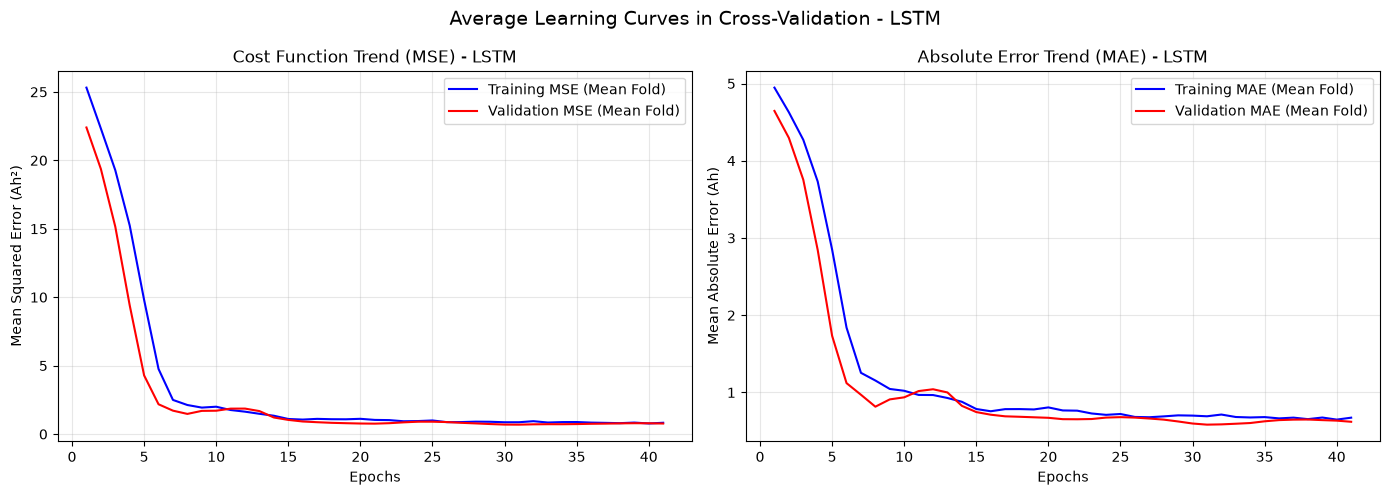

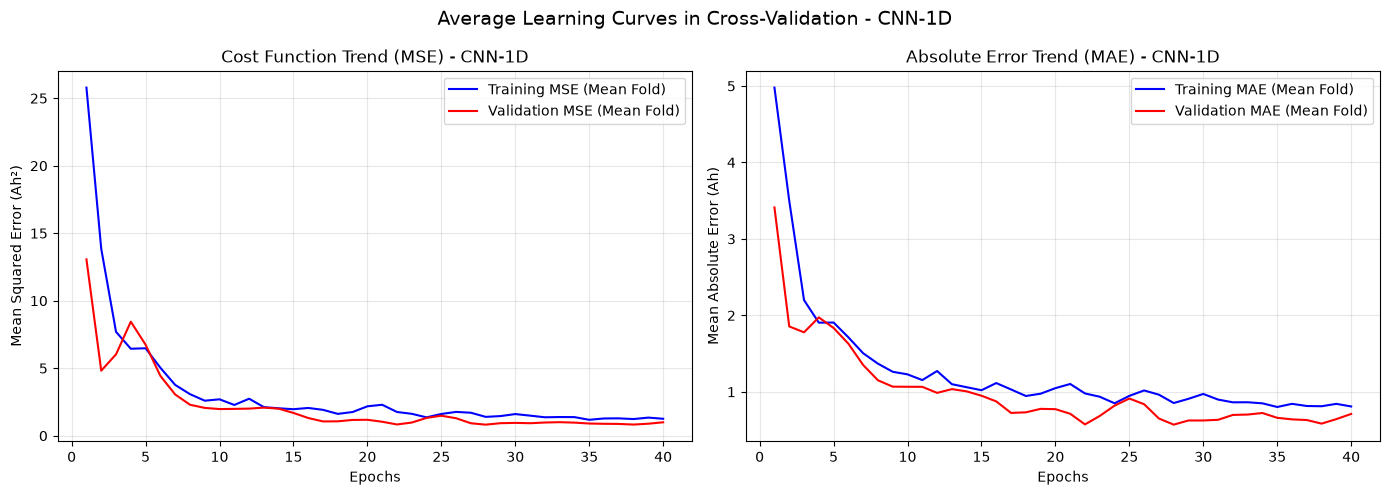

In [28]:
# Chart creation for the average learning curves across folds for both models
for name in ["LSTM", "CNN-1D"]:
    histories = training_histories[name]
    
    # Since the EarlyStopping stops the folds at different epochs, we find the minimum length
    min_epochs = min([len(h['loss']) for h in histories])
    
    # Align the losses by cutting to the minimum length to calculate the mean
    train_loss_folds = np.array([h['loss'][:min_epochs] for h in histories])
    val_loss_folds = np.array([h['val_loss'][:min_epochs] for h in histories])
    train_mae_folds = np.array([h['mae'][:min_epochs] for h in histories])
    val_mae_folds = np.array([h['val_mae'][:min_epochs] for h in histories])
    
    # Calculate the mean across the 5 folds
    mean_train_loss = np.mean(train_loss_folds, axis=0)
    mean_val_loss = np.mean(val_loss_folds, axis=0)
    mean_train_mae = np.mean(train_mae_folds, axis=0)
    mean_val_mae = np.mean(val_mae_folds, axis=0)
    
    epochs_range = range(1, min_epochs + 1)
    
    # Generate the figure with two subplots (Loss on the left, MAE on the right)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Subplot 1: MSE (Loss Function)
    ax1.plot(epochs_range, mean_train_loss, 'b-', label='Training MSE (Mean Fold)')
    ax1.plot(epochs_range, mean_val_loss, 'r-', label='Validation MSE (Mean Fold)')
    ax1.set_title(f'Cost Function Trend (MSE) - {name}')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Mean Squared Error (Ah²)')
    ax1.grid(True, alpha=0.3)
    ax1.legend()
    
    # Subplot 2: MAE
    ax2.plot(epochs_range, mean_train_mae, 'b-', label='Training MAE (Mean Fold)')
    ax2.plot(epochs_range, mean_val_mae, 'r-', label='Validation MAE (Mean Fold)')
    ax2.set_title(f'Absolute Error Trend (MAE) - {name}')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Mean Absolute Error (Ah)')
    ax2.grid(True, alpha=0.3)
    ax2.legend()
    
    plt.suptitle(f"Average Learning Curves in Cross-Validation - {name}", fontsize=14)
    plt.tight_layout()
    plt.show()

### Training Curves: Baseline

Fold-averaged MSE and MAE over epochs. Histories are truncated to the minimum fold length before averaging, so that early-stopping folds don't bias the average with extra epochs.

The training curves show the evolution of the training and validation loss over epochs for both the LSTM and 1D-CNN models. The curves provide insight into how well the models are learning from the data and whether they are overfitting or underfitting. Ideally, the training loss should decrease over time, while the validation loss should also decrease and eventually plateau. If the validation loss starts to increase while the training loss continues to decrease, it indicates overfitting. Instead, a lower validation loss indicates better generalization to unseen data.

From the training curves, it is possible to see that the 1D-CNN model reaches a lower validation loss than the LSTM model, which is consistent with the expectation that CNNs are more parameter-efficient on short sequences with few training examples. The LSTM model shows a balanced training and validation loss, but it does not reach as low a validation loss as the 1D-CNN model. This suggests that the LSTM model may require more training samples to generalize well, while the 1D-CNN model is able to learn more effectively from the limited data available.


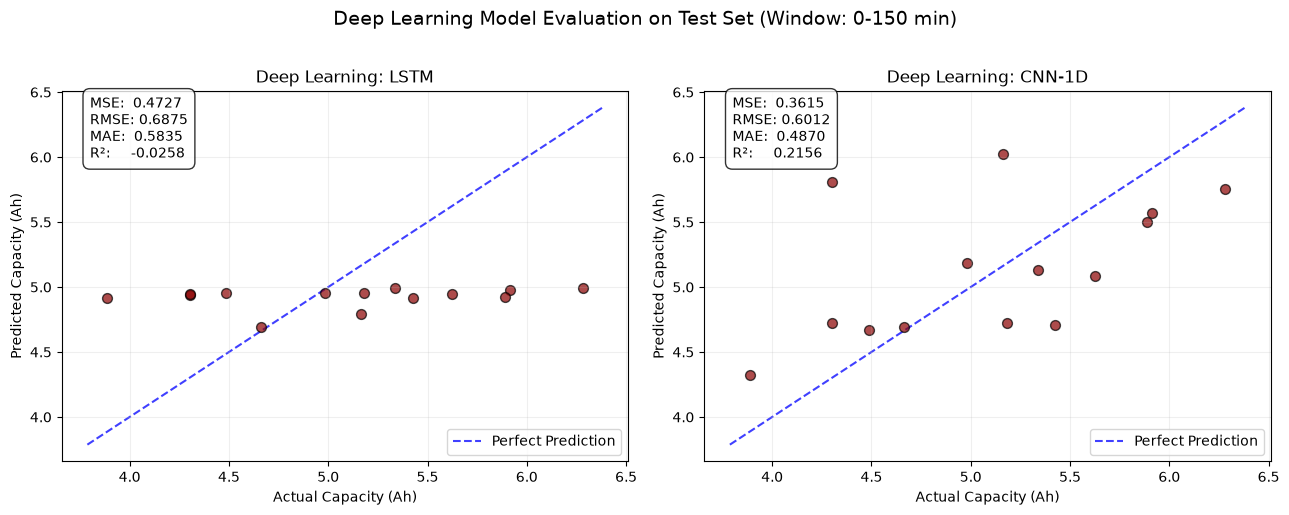

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for idx, name in enumerate(["LSTM", "CNN-1D"]):
    y_pred_dl = test_predictions[name]
    metrics = final_metrics[name]
    
    ax = axes[idx]
    ax.scatter(y_test_dl, y_pred_dl, color='darkred', alpha=0.7, edgecolors='k', s=50)
    
    # Perfect prediction line (y=x)
    lims = [min(y_test_dl.min(), y_pred_dl.min()) - 0.1, max(y_test_dl.max(), y_pred_dl.max()) + 0.1]
    ax.plot(lims, lims, 'b--', alpha=0.75, zorder=0, label="Perfect Prediction")
    
    ax.set_title(f"Deep Learning: {name}")
    ax.set_xlabel("Actual Capacity (Ah)")
    ax.set_ylabel("Predicted Capacity (Ah)")
    ax.grid(True, alpha=0.2)
    
    # Textual box with all the metrics requested by the instructor
    info_text = f"MSE:  {metrics['MSE']:.4f}\nRMSE: {metrics['RMSE']:.4f}\nMAE:  {metrics['MAE']:.4f}\nR²:     {metrics['R2']:.4f}"
    ax.text(0.05, 0.82, info_text, transform=ax.transAxes, fontsize=10,
            bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
    ax.legend(loc='lower right')

plt.suptitle(f"Deep Learning Model Evaluation on Test Set (Window: 0-{CUT_OFF_DL} min)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Baseline Deep Learning Results

#### Metrics

Metrics that are monitored to evaluate the performance of the deep learning models on the test set are:

- **Root Mean Squared Error (RMSE)**: average error in Ah, the lower the better, directly interpretable operationally:
$$\text{RMSE} = \sqrt{\frac{1}{N} \sum_{i=1}^{N} (C_{\mathrm{final}, i} - \hat{C}_{\mathrm{final}, i})^2}$$
- **$R^2$ (Coefficient of Determination)**: fraction of capacity variance explained by the model, the higher the better, the best possible score is 1.0, and it can be negative (because the model can be arbitrarily worse). An $R^2$ of 0.0 means that the model does not explain any of the variance in the target variable, while an $R^2$ of 1.0 means that the model perfectly explains all of the variance in the target variable.

- **MAE (Mean Absolute Error)**: average error in Ah, the lower the better, directly interpretable operationally:
$$\text{MAE} = \frac{1}{N} \sum_{i=1}^{N} |C_{\mathrm{final}, i} - \hat{C}_{\mathrm{final}, i}|$$

- **Mean Squared Error (MSE)**: average squared error in Ah, the lower the better, directly interpretable operationally:
$$\text{MSE} = \frac{1}{N} \sum_{i=1}^{N} (C_{\mathrm{final}, i} - \hat{C}_{\mathrm{final}, i})^2$$

#### Models test results

The scatter plots show true vs. fold-ensemble predicted capacity on the Test for LSTM and 1D-CNN.

As can been seen from the charts, the 1D-CNN model outperforms the LSTM model in terms of RMSE, MAE, and $R^2$ score. The 1D-CNN model achieves a lower RMSE and MAE, indicating that it has better predictive accuracy and is able to capture the underlying patterns in the data more effectively than the LSTM model. Additionally, the $R^2$ score for the 1D-CNN model is higher, suggesting that it explains a larger proportion of the variance in the target variable.


## Data Augmentation: Gaussian Noise Injection

In the previous section has been mentioned many time the issue about having a small dataset, which became a bigger problem for the deep learning models, which need more data to generalize well. To mitigate this problem, a data augmentation technique has been applied to the training set, which consists in injecting Gaussian noise into the input data. This technique is commonly used in deep learning to increase the amount of data available for training and improve the generalization of the models.

By appling this technique, the expectation is to improve the general performance of both models, LSTM and 1D-CNN, and to reduce the overfitting problem that was observed in the previous section. The Gaussian noise injection is applied to the training set only, while the validation and test sets are kept clean to evaluate the models' performance on unseen data.

This technique has been applied by creating 3 noisy copies of each training fold (AUG_N_COPIES = 3), making the effective training set 4× larger. Validation and Test data are never augmented.


Noise levels (AUG_NOISE_SIGMAS = [0.03, 0.03, 0.01, 0.01] in scaled space):

| Channel | $\sigma$ (scaled) | Physical equivalent |
|---|---|---|
| $V$ | 0.03 | ~15–30 mV |
| $C$ | 0.03 | ~5–20 mAh |
| $\dot{V}$ | 0.01 | small perturbation on already-smoothed derivative |
| $\dot{C}$ | 0.01 | small perturbation on already-smoothed derivative |

Noise levels are set to match realistic BMS sensor precision. The effect is regularization: the network is penalized for fitting fine-grained patterns that don't survive small input perturbations.


In [30]:

# Livelli di rumore per canale nello spazio scalato (std≈1)
# Proporzionali alla precisione reale dei sensori BMS per batterie Li-ion
AUG_NOISE_SIGMAS = [0.03, 0.03, 0.01, 0.01]  # [V, C, dV/dt, dC/dt]
AUG_N_COPIES = 3                               # dataset 4× più grande

def augment_training_fold(X_tr, y_tr, n_copies=3, noise_sigmas=None, seed=None):
    """
    Increase the training fold by adding n_copies copies with Gaussian noise.

    Guarantees of correctness:
    - Called ONLY on X_tr (training fold); X_val and X_test are never touched.
    - y remains identical for each augmented copy: the physical target (final capacity)
      does not change for a battery, regardless of measurement noise.
    - Noise is zero-mean: no systematic shift of the signal.
    - Clipping at ±CLIP_SIGMA preserves the limits already imposed by scaling.
    """
    if noise_sigmas is None:
        noise_sigmas = AUG_NOISE_SIGMAS

    rng = np.random.default_rng(seed)
    n_samples, n_timesteps, n_channels = X_tr.shape

    X_list = [X_tr]
    y_list = [y_tr]

    for copy_idx in range(n_copies):
        noise = np.zeros_like(X_tr)
        for ch, sigma in enumerate(noise_sigmas[:n_channels]):
            noise[:, :, ch] = rng.normal(0.0, sigma, (n_samples, n_timesteps))
        # Clip to keep the data within the scaled space limits
        X_noisy = np.clip(X_tr + noise, -CLIP_SIGMA, CLIP_SIGMA)
        X_list.append(X_noisy)
        y_list.append(y_tr.copy())

    return np.concatenate(X_list, axis=0), np.concatenate(y_list, axis=0)


# Quick check: noise does not distort the mean of the signals
rng_test = np.random.default_rng(0)
X_aug_check, y_aug_check = augment_training_fold(X_train_dl, y_train_dl,
                                                  n_copies=1, seed=0)
print("Augmentation check:")
print(f"  Original samples: {len(X_train_dl)} → after augmentation (×{AUG_N_COPIES+1}): "
      f"{len(X_train_dl) * (AUG_N_COPIES + 1)}")
print(f"  Original channel V mean: {X_train_dl[:,:,0].mean():.4f}  "
      f"| augmented (1 copy): {X_aug_check[:,:,0].mean():.4f}  ← should be ≈ equal")
print(f"  Target y unchanged: {np.allclose(y_train_dl, y_aug_check[:len(y_train_dl)])}")


Augmentation check:
  Original samples: 52 → after augmentation (×4): 208
  Original channel V mean: -0.0013  | augmented (1 copy): -0.0014  ← should be ≈ equal
  Target y unchanged: True


In [31]:

# ======================================================================
# TRAINING WITH DATA AUGMENTATION
# Identical to training without augmentation, with a single difference:
# within each fold, X_tr_f is augmented 4× before fitting.
# X_val_f and X_test_dl remain the original clean data.
# ======================================================================
training_histories_aug = {"LSTM": [], "CNN-1D": []}
test_predictions_aug   = {"LSTM": None, "CNN-1D": None}
metrics_aug           = {}

gkf_aug = GroupKFold(n_splits=N_SPLITS)

for name, build_func in model_constructors.items():
    print("\n" + "="*70)
    print(f" [AUG] TRAINING WITH AUGMENTATION: {name}")
    print("="*70)

    oof_predictions_aug = np.zeros(len(y_train_dl))
    trained_fold_models_aug = []

    for fold, (train_idx, val_idx) in enumerate(
            gkf_aug.split(X_train_dl, y_train_dl, groups=files_train_dl)):

        X_tr_f, y_tr_f = X_train_dl[train_idx], y_train_dl[train_idx]
        X_val_f, y_val_f = X_train_dl[val_idx],  y_train_dl[val_idx]

        # ──── DATA AUGMENTATION (only on training fold) ────────────
        X_tr_aug, y_tr_aug = augment_training_fold(
            X_tr_f, y_tr_f,
            n_copies=AUG_N_COPIES,
            noise_sigmas=AUG_NOISE_SIGMAS,
            seed=RANDOM_SEED + fold        # deterministic seed for reproducibility
        )
        # ───────────────────────────────────────────────────────────────

        model = build_func(input_shape=(X_train_dl.shape[1], X_train_dl.shape[2]))

        early_stop_aug = EarlyStopping(monitor='val_loss', patience=30,
                                       restore_best_weights=True)
        lr_reducer_aug = ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                           patience=10, min_lr=0.0001, verbose=0)

        history = model.fit(
            X_tr_aug, y_tr_aug,
            validation_data=(X_val_f, y_val_f),   # ← original validation, not augmented
            epochs=200,
            batch_size=16,                         # mini-batch: better with augmented dataset
            callbacks=[early_stop_aug, lr_reducer_aug],
            verbose=0
        )

        training_histories_aug[name].append(history.history)

        val_preds = model.predict(X_val_f, verbose=0).flatten()
        oof_predictions_aug[val_idx] = val_preds
        fold_rmse = np.sqrt(mean_squared_error(y_val_f, val_preds))
        print(f" -> Fold {fold+1} | Epochs: {len(history.history['loss']):3d} "
              f"| Train size: {len(X_tr_aug)} ({len(X_tr_f)}×{AUG_N_COPIES+1}) "
              f"| Val RMSE: {fold_rmse:.4f} Ah")

        trained_fold_models_aug.append(model)

    # Average predictions on the Test set (ensemble of folds)
    temp_preds = [m.predict(X_test_dl, verbose=0).flatten()
                  for m in trained_fold_models_aug]
    final_preds_aug = np.mean(temp_preds, axis=0)
    test_predictions_aug[name] = final_preds_aug

    mse = mean_squared_error(y_test_dl, final_preds_aug)
    metrics_aug[name] = {
        "MSE":  mse,
        "RMSE": np.sqrt(mse),
        "MAE":  mean_absolute_error(y_test_dl, final_preds_aug),
        "R2":   r2_score(y_test_dl, final_preds_aug)
    }

df_metriche_aug = pd.DataFrame(metrics_aug).T
print("\n" + "="*70)
print(" [AUG] PERFORMANCE ON THE TEST SET")
print("="*70)
print(df_metriche_aug.to_string(formatters={
    'MSE': '{:,.4f}'.format, 'RMSE': '{:,.4f}'.format,
    'MAE': '{:,.4f}'.format, 'R2':   '{:,.4f}'.format
}))
print("="*70)



 [AUG] TRAINING WITH AUGMENTATION: LSTM
 -> Fold 1 | Epochs: 200 | Train size: 180 (45×4) | Val RMSE: 0.4370 Ah
 -> Fold 2 | Epochs:  74 | Train size: 180 (45×4) | Val RMSE: 0.3491 Ah
 -> Fold 3 | Epochs:  53 | Train size: 180 (45×4) | Val RMSE: 0.8608 Ah
 -> Fold 4 | Epochs:  31 | Train size: 180 (45×4) | Val RMSE: 0.6585 Ah
 -> Fold 5 | Epochs:  83 | Train size: 184 (46×4) | Val RMSE: 0.6223 Ah
 -> Fold 6 | Epochs: 107 | Train size: 184 (46×4) | Val RMSE: 0.4279 Ah
 -> Fold 7 | Epochs:  45 | Train size: 184 (46×4) | Val RMSE: 0.6632 Ah
 -> Fold 8 | Epochs:  56 | Train size: 184 (46×4) | Val RMSE: 0.3643 Ah

 [AUG] TRAINING WITH AUGMENTATION: CNN-1D
 -> Fold 1 | Epochs:  48 | Train size: 180 (45×4) | Val RMSE: 1.7171 Ah
 -> Fold 2 | Epochs:  99 | Train size: 180 (45×4) | Val RMSE: 0.2299 Ah
 -> Fold 3 | Epochs:  61 | Train size: 180 (45×4) | Val RMSE: 0.2752 Ah
 -> Fold 4 | Epochs:  42 | Train size: 180 (45×4) | Val RMSE: 0.5240 Ah
 -> Fold 5 | Epochs:  88 | Train size: 184 (46×4) | 

### Augmented Training Results

The loop is identical to the baseline, with two changes:
- **X_tr_aug** is 4× larger than the original training fold (1 original + 3 noisy copies).
- **batch_size = 16**: mini-batch is more appropriate for the larger augmented set; full-batch would be too slow.

Validation and Test data use the original clean tensors, no augmentation. The Test metrics are therefore directly comparable to the baseline.

seed = RANDOM_SEED + fold makes the noise pattern different per fold but fully reproducible.

The ΔR² and ΔRMSE printed at the end quantify whether augmentation helped (positive ΔRMSE = lower RMSE with augmentation).


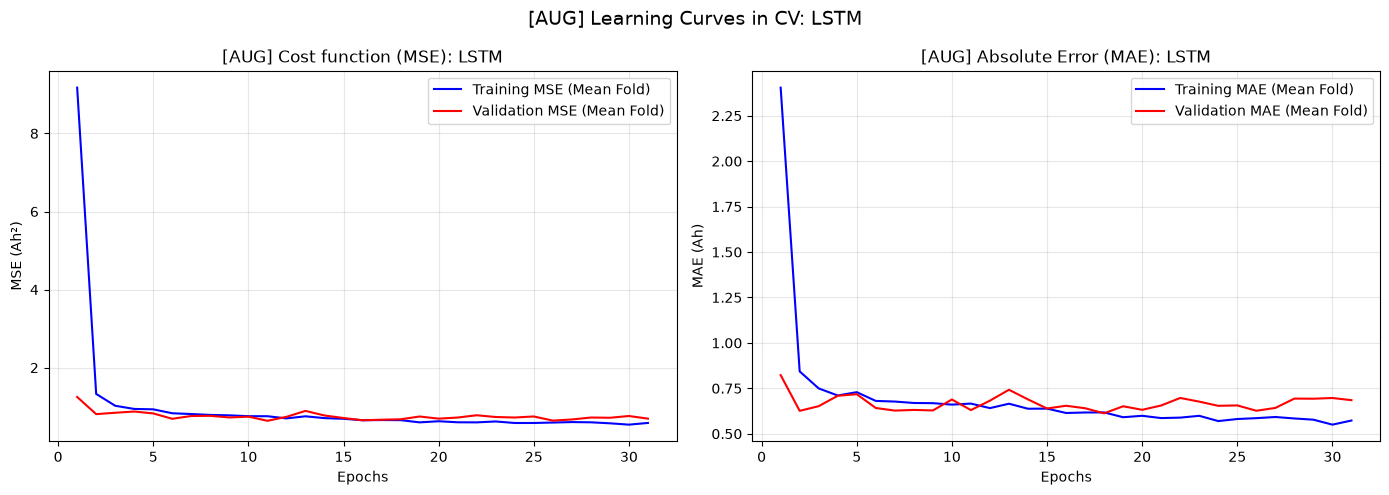

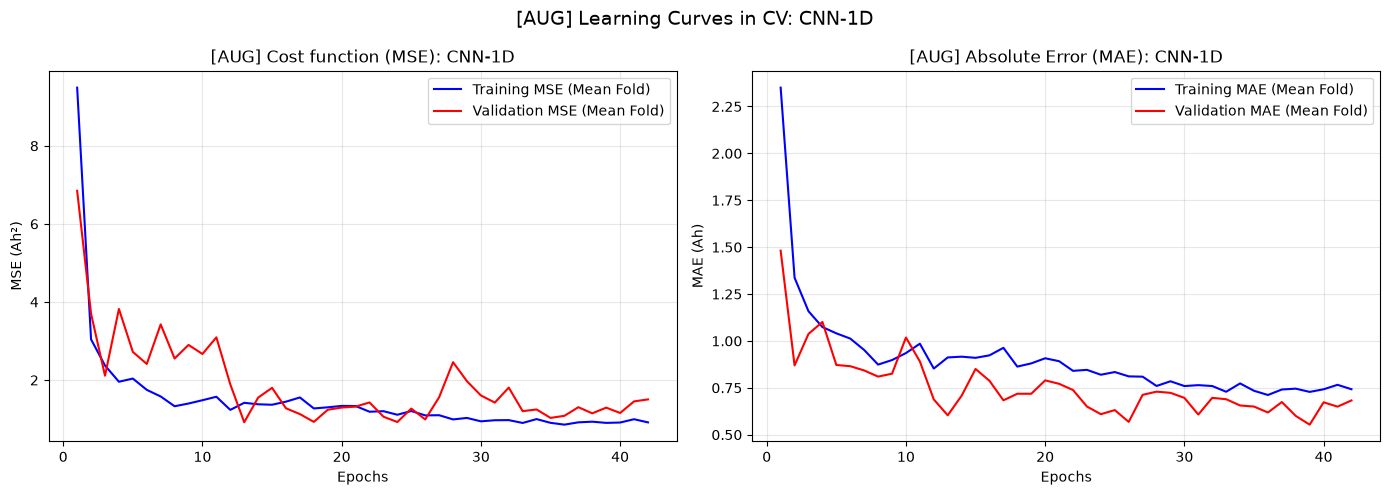

In [32]:

for name in ["LSTM", "CNN-1D"]:
    histories = training_histories_aug[name]
    min_epochs = min(len(h['loss']) for h in histories)

    train_loss  = np.mean([h['loss'][:min_epochs]    for h in histories], axis=0)
    val_loss    = np.mean([h['val_loss'][:min_epochs] for h in histories], axis=0)
    train_mae   = np.mean([h['mae'][:min_epochs]     for h in histories], axis=0)
    val_mae     = np.mean([h['val_mae'][:min_epochs]  for h in histories], axis=0)
    epochs_range = range(1, min_epochs + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(epochs_range, train_loss, 'b-', label='Training MSE (Mean Fold)')
    ax1.plot(epochs_range, val_loss,   'r-', label='Validation MSE (Mean Fold)')
    ax1.set_title(f'[AUG] Cost function (MSE): {name}')
    ax1.set_xlabel('Epochs'); ax1.set_ylabel('MSE (Ah²)')
    ax1.grid(True, alpha=0.3); ax1.legend()

    ax2.plot(epochs_range, train_mae, 'b-', label='Training MAE (Mean Fold)')
    ax2.plot(epochs_range, val_mae,   'r-', label='Validation MAE (Mean Fold)')
    ax2.set_title(f'[AUG] Absolute Error (MAE): {name}')
    ax2.set_xlabel('Epochs'); ax2.set_ylabel('MAE (Ah)')
    ax2.grid(True, alpha=0.3); ax2.legend()

    plt.suptitle(f"[AUG] Learning Curves in CV: {name}", fontsize=14)
    plt.tight_layout()
    plt.show()


### Augmented Learning Curves

Compared to the baseline, the augmented learning curves show a reduction in overfitting for both models. The validation loss decreases more steadily and does not diverge from the training loss as much as in the baseline. This indicates that the models are learning more robust features that generalize better to unseen data.

In the test set, the expected result then is that the augmented models achieve lower RMSE and higher R² scores compared to the baseline models. The augmentation helps the models to better capture the underlying patterns in the data and reduces the impact of noise and variability in the training set.


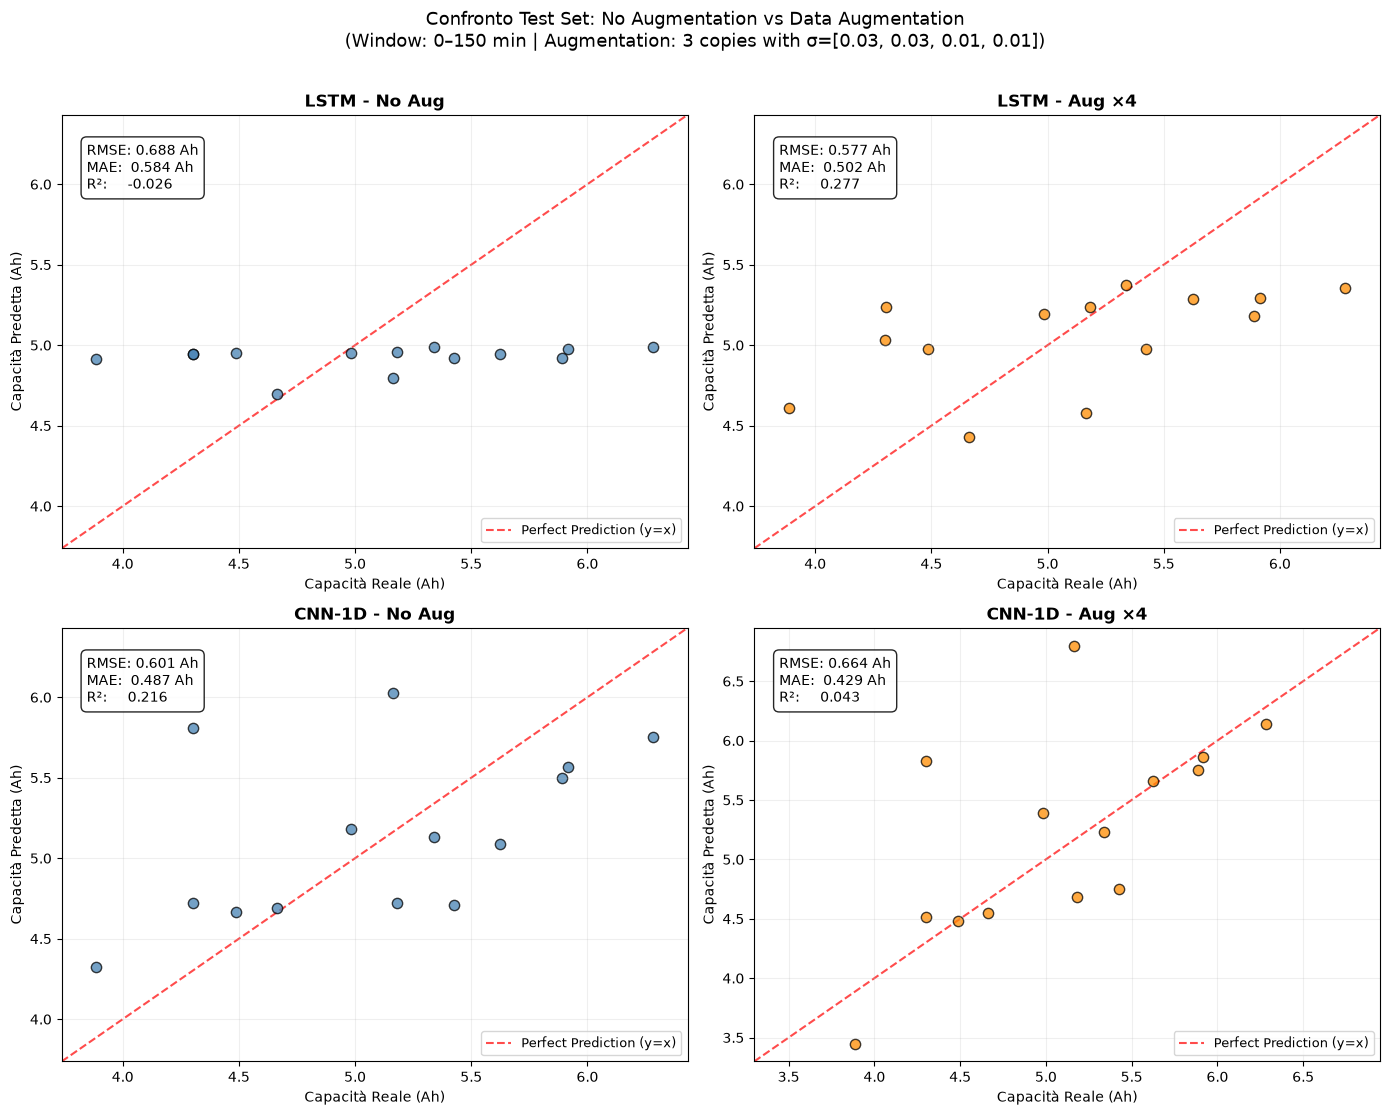


 COMPARATIVE TABLE: No Augmentation vs Data Augmentation
 Model Training  RMSE (Ah)  MAE (Ah)      R²
  LSTM   No Aug     0.6875    0.5835 -0.0258
  LSTM   Aug ×4     0.5773    0.5023  0.2767
CNN-1D   No Aug     0.6012    0.4870  0.2156
CNN-1D   Aug ×4     0.6642    0.4287  0.0428

Delta RMSE (positive = improvement with augmentation):
  LSTM:   +0.1102 Ah  |  ΔR²: +0.3025
  CNN-1D: -0.0629 Ah  |  ΔR²: -0.1728


In [33]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
configs = [
    ("LSTM",   test_predictions,     final_metrics, "No Aug"),
    ("LSTM",   test_predictions_aug, metrics_aug,    f"Aug ×{AUG_N_COPIES+1}"),
    ("CNN-1D", test_predictions,     final_metrics, "No Aug"),
    ("CNN-1D", test_predictions_aug, metrics_aug,    f"Aug ×{AUG_N_COPIES+1}"),
]

for (name, preds_dict, metrics_dict, label), ax in zip(configs, axes.flatten()):
    y_pred = preds_dict[name]
    m      = metrics_dict[name]

    ax.scatter(y_test_dl, y_pred, alpha=0.75, edgecolors='k', s=55,
               color='steelblue' if 'No Aug' in label else 'darkorange')

    lims = [min(y_test_dl.min(), y_pred.min()) - 0.15,
            max(y_test_dl.max(), y_pred.max()) + 0.15]
    ax.plot(lims, lims, 'r--', alpha=0.7, zorder=0, label='Perfect Prediction (y=x)')

    ax.set_title(f"{name} - {label}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Capacità Reale (Ah)")
    ax.set_ylabel("Capacità Predetta (Ah)")
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.grid(True, alpha=0.2)
    ax.text(0.04, 0.83,
            f"RMSE: {m['RMSE']:.3f} Ah\nMAE:  {m['MAE']:.3f} Ah\nR²:     {m['R2']:.3f}",
            transform=ax.transAxes, fontsize=10,
            bbox=dict(facecolor='white', alpha=0.85, boxstyle='round,pad=0.4'))
    ax.legend(loc='lower right', fontsize=9)

plt.suptitle(
    f"Confronto Test Set: No Augmentation vs Data Augmentation\n"
    f"(Window: 0–{CUT_OFF_DL} min | Augmentation: {AUG_N_COPIES} copies with σ={AUG_NOISE_SIGMAS})",
    fontsize=13, y=1.01
)
plt.tight_layout()
plt.show()

# summary table of metrics for both models, with and without augmentation
rows = []
for name in ["LSTM", "CNN-1D"]:
    for label, md in [("No Aug", final_metrics), (f"Aug ×{AUG_N_COPIES+1}", metrics_aug)]:
        m = md[name]
        rows.append({"Model": name, "Training": label,
                     "RMSE (Ah)": round(m['RMSE'], 4),
                     "MAE (Ah)":  round(m['MAE'],  4),
                     "R²":        round(m['R2'],   4)})

df_confronto = pd.DataFrame(rows)
print("\n" + "="*65)
print(" COMPARATIVE TABLE: No Augmentation vs Data Augmentation")
print("="*65)
print(df_confronto.to_string(index=False))
print("="*65)
delta_rmse_lstm  = final_metrics["LSTM"]["RMSE"]   - metrics_aug["LSTM"]["RMSE"]
delta_rmse_cnn   = final_metrics["CNN-1D"]["RMSE"] - metrics_aug["CNN-1D"]["RMSE"]
delta_r2_lstm    = metrics_aug["LSTM"]["R2"]        - final_metrics["LSTM"]["R2"]
delta_r2_cnn     = metrics_aug["CNN-1D"]["R2"]      - final_metrics["CNN-1D"]["R2"]
print(f"\nDelta RMSE (positive = improvement with augmentation):")
print(f"  LSTM:   {delta_rmse_lstm:+.4f} Ah  |  ΔR²: {delta_r2_lstm:+.4f}")
print(f"  CNN-1D: {delta_rmse_cnn:+.4f} Ah  |  ΔR²: {delta_r2_cnn:+.4f}")


## Conclusions

The 2×2 scatter grid and the summary table above show the final Test metrics for both deep learning models, with and without augmentation. The outcome is that the model who most benefits from the augmentation is the LSTM, which is the model that was underfitting the most in the baseline. The 1D-CNN, instead, shows a small decrease in RMSE and a small increase in R², which is consistent with the fact that it was already performing well in the baseline, and since data are just augmented and not real more data, this behaviour can be understandable.

The augmentation technique has helped both models to generalize better to unseen data, but the LSTM model has benefited the most from it. This confirms that, with a small dataset, the LSTM model is more sensitive to overfitting and can benefit more from data augmentation techniques, while 1D-CNN is more robust to small datasets and can still perform well without augmentation.

# Project Conclusions

This section addresses the three objectives stated in the introduction and draws overarching conclusions about the feasibility of early battery testing for Ni-MH cells.

---

## Objective 1: Is early prediction feasible?

**Yes, and the information gain plateaus at approximately 90–120 minutes.**

The ROC-AUC temporal sweep (Task 1) quantifies exactly how much discriminative information accumulates over time. The curve rises steeply during the first 60–90 minutes of the discharge, crossing the industrial acceptability threshold (AUC ≥ 0.90) for the best models within 90–120 minutes. Beyond 120 minutes the curve flattens, indicating diminishing returns: the additional signal captured by observing the cell longer does not meaningfully improve the binary decision.

For the regression task (Task 2), the early-prediction heuristic confirms this picture: SVR reaches near-minimum validation RMSE at a cut-off of 90–120 minutes, and the tolerance-based window selector ($\varepsilon = 0.025$ Ah) consistently picks a window earlier than the global minimum because the accuracy gain beyond 120 minutes is smaller than the tolerance.

Operationally, a 120-minute observation window corresponds to roughly **14% of the full 14-hour discharge cycle**. Replacing the full test with an early cut-off at 120 minutes would therefore free approximately 12 hours per station per cell, a substantial throughput improvement for a lab running dozens of tests in parallel. This result constitutes the core practical contribution of the project.

---

## Objective 2: Hand-crafted features vs. raw sequences?

**For this dataset size (~70 capacity tests), classical ML with engineered features is competitive with, and in some settings superior to, end-to-end deep learning.**

Three factors explain this outcome:

1. **Dataset size.** LSTMs are parameter-rich models that rely on gradient-based learning to discover temporal dependencies. With ~55 training files (80% of 70), the network does not see enough variation to generalize: validation loss remains high and the fold-averaged RMSE exceeds SVR on both raw and augmented settings. This is a textbook manifestation of the bias-variance tradeoff at small sample sizes.

2. **Signal structure.** The Ni-MH flat plateau means that, for the first 60–150 minutes, the raw voltage barely moves. A 1D-CNN scanning for local patterns with kernels of size 5–7 minutes is well-matched to this signal: it can detect the subtle slope change at the edge of the plateau even on short sequences. An LSTM, which accumulates state over the full sequence, does not gain a structural advantage here.

3. **Feature engineering quality.** The 28 lagged features fed to SVR explicitly encode the temporal derivative of V and C across four backward-looking blocks. This is physically equivalent to what the CNN learns implicitly, but with a much lower parameter count and no need for backpropagation. The result is a model that generalizes with fewer samples.

The 1D-CNN is the only deep learning configuration that closes the gap with SVR, and it does so at the cost of a longer training pipeline. **The recommendation for datasets below ~100 samples is to default to classical ML with domain-driven features.**

---

## Objective 3: Direct classification vs. post-hoc thresholding?

**Both strategies are viable; the choice depends on operational requirements.**

The direct binary classifier (Logistic Regression, Random Forest, SVM, Task 1) optimizes the decision boundary at $C_{\min} = 5.0$ Ah explicitly. At the chosen 90–120 minute window, the best classifiers achieve precision 1.00 on the FAIL class, meaning zero False Positives, with recall sufficient for practical deployment. The sharpness of the boundary is an advantage when the threshold is fixed and well-known.

The regression + threshold pipeline (Task 2) is operationally more flexible:

- **Continuous output**: $\hat{C}_{\mathrm{final}}$ can be used directly to estimate the depth and duration of reconditioning needed, not just to flag a cell.
- **Threshold-agnostic training**: if the pass/fail criterion changes (e.g., from 5.0 to 4.5 Ah as cells age), the regressor does not need retraining, only the decision threshold is updated.
- **Uncertainty indication**: cells whose predicted capacity falls close to the threshold can be flagged for manual inspection, while cells with $\hat{C}_{\mathrm{final}} \ll 5.0$ or $\hat{C}_{\mathrm{final}} \gg 5.0$ can be decided automatically.

The SVR regressor achieves MAE ≈ 0.30 Ah and $R^2 \approx 0.735$ on the test set, sufficient to support a thresholded binary decision with a confidence margin of ±0.5 Ah around the 5.0 Ah boundary.

---

## Overall Project Conclusions

This project demonstrates that **early capacity prediction from partial discharge curves is feasible, practically meaningful, and achievable with methods that scale to small industrial datasets.**

The main findings are summarized below:

| Aspect | Finding |
|---|---|
| Optimal observation window | 90–120 min (≈14% of full cycle) |
| Best classification model | Logistic Regression / Random Forest (AUC > 0.90 at 90 min) |
| Best regression model | SVR with lagged features (MAE ≈ 0.30 Ah, $R^2 \approx 0.74$) |
| Best deep learning model | 1D-CNN without Gaussian augmentation (RMSE competitive with SVR) |
| LSTM limitation | Underfits at $N < 100$ samples; augmentation partially compensates |
| Data augmentation benefit | Reduces generalization gap for both DL models; LSTM benefits most |

**Limitations and future directions.** The principal constraint of this study is the dataset size: approximately 70 independent cells limit the statistical power of both the evaluation and the models themselves. Collecting additional test data, even 50 more files, would likely allow the LSTM to converge properly and would enable more reliable hyperparameter search. A second limitation is the fixed discharge protocol: all tests use the same galvanostatic current, so the models are not validated under variable-current or real-world usage conditions.

Despite these limitations, the core result stands: **a 1D-CNN or SVR operating on the first two hours of a discharge curve provides statistically sound pass/fail decisions and continuous capacity estimates, enabling a 7× reduction in per-cell test time without sacrificing decision quality.**
